# Experiment 08b — Training–validation gap in isotropic shielding

Evaluate **both experiment 07 (ordinary MSE) and experiment 08 (3× coordination weighting)**, using their saved best checkpoints, on **all 800 training structures and all 50 validation structures**. Every reported error is unweighted and in ppm. This is fresh inference; no retraining, offset refitting, calibration or test-set access occurs. The target is absolute isotropic shielding `MS_Iso_QM = trace(ms)/3`, one scalar per atom.

The purpose is to distinguish poor fitting of training environments from poor generalisation to validation environments. Compare exact coordination categories and normal atoms near/far from defects. Training and validation cohorts differ: a gap can reflect different difficulty or coverage, and is not proof of a unique cause. The validation set already selected these checkpoints. All indices are zero-based.

Run all cells with the project's `.venv` Python. Predictions for both models across 850 structures take several minutes on CPU. Models and data are read only. Tables and figures are embedded below; rerunning computes predictions afresh.


In [1]:
from pathlib import Path
from importlib.metadata import version
from datetime import datetime, timezone
import hashlib
import json
import os
import platform
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import yaml
from ase.io import read
from graph_pes.atomic_graph import AtomicGraph
from graph_pes.utils.nn import count_used_parameters
from IPython.display import display, Markdown

RUN_NAME = 'TensorNequIP-NMR-Coord3x-9083627'
candidates = ([Path(os.environ['NEQUIP_PROJECT'])] if 'NEQUIP_PROJECT' in os.environ else [])
candidates += [Path.cwd(), *Path.cwd().parents,
               Path('/Users/louismcauliffe/code/research/NequIP_experiments')]
PROJECT = next((p.resolve() for p in candidates
                if (p / 'graph-pes-results' / RUN_NAME / 'model.pt').is_file()), None)
if PROJECT is None:
    raise FileNotFoundError('Set NEQUIP_PROJECT to the NequIP_experiments directory.')
sys.path.insert(0, str(PROJECT))
# Required to unpickle the trusted local model; importing does not generate data.
import nmr_helpers

RUN = PROJECT / 'graph-pes-results' / RUN_NAME
SPLITS = ['train', 'valid']
ELEMENTS = ['Si', 'O']
COLOURS = {'Si': '#2769a4', 'O': '#d56831'}
PATHS = {split: PROJECT / 'data/nmr_iso' / f'{split}.xyz' for split in SPLITS}
THREADS = 2
torch.set_num_threads(THREADS)
torch.set_default_dtype(torch.float32)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 160)

def sha256(path):
    with open(path, 'rb') as stream:
        return hashlib.file_digest(stream, 'sha256').hexdigest()

versions = {name: version(name) for name in ['graph-pes', 'torch', 'e3nn', 'ase', 'numpy', 'pandas']}
print('Project:', PROJECT)
print('Inference: CPU, float32,', THREADS, 'threads |', platform.machine())
print('Versions:', versions)


Project: /Users/louismcauliffe/code/research/NequIP_experiments
Inference: CPU, float32, 2 threads | arm64
Versions: {'graph-pes': '1.0.2', 'torch': '2.6.0', 'e3nn': '0.4.4', 'ase': '3.29.0', 'numpy': '2.4.6', 'pandas': '3.0.6'}


## 1. Verify datasets and labels

Audit training and validation labels, units, counts and exact rounded-coordinate duplicates. This is not a symmetry-aware or trajectory-independence test.


In [2]:
structures = {split: read(path, index=':', format='extxyz') for split, path in PATHS.items()}
data_hashes = {split: sha256(path) for split, path in PATHS.items()}

def geometry_key(atoms):
    digest = hashlib.sha256()
    for array in [np.asarray(atoms.numbers, dtype='<i8'),
                  np.round(atoms.positions, 6).astype('<f8'),
                  np.round(atoms.cell.array, 6).astype('<f8'), atoms.pbc.astype('u1')]:
        digest.update(np.ascontiguousarray(array).tobytes())
    return digest.hexdigest()

audit_rows, fingerprint_sets = [], {}
for split, frames in structures.items():
    assert frames, f'Empty {split} split'
    max_trace_error = 0.0
    fingerprints = []
    for frame in frames:
        labels = np.asarray(frame.arrays['MS_Iso_QM'], dtype=np.float64)
        tensors = np.asarray(frame.arrays['ms'], dtype=np.float64).reshape(len(frame), 3, 3)
        expected = np.trace(tensors, axis1=1, axis2=2) / 3
        assert labels.shape == (len(frame),) and np.isfinite(labels).all()
        assert frame.info['magres_units']['ms'] == 'ppm'
        assert set(frame.get_chemical_symbols()) <= set(ELEMENTS)
        max_trace_error = max(max_trace_error, float(np.max(np.abs(labels - expected))))
        assert np.allclose(labels, expected, rtol=0, atol=1e-7)
        fingerprints.append(geometry_key(frame))
    fingerprint_sets[split] = set(fingerprints)
    row = {'split': split, 'structures': len(frames), 'sites': sum(map(len, frames)),
           'duplicate_frames': len(frames) - len(set(fingerprints)),
           'max_trace_error_ppm': max_trace_error}
    for element in ELEMENTS:
        row[element + '_sites'] = sum(np.sum(np.array(f.get_chemical_symbols()) == element) for f in frames)
    audit_rows.append(row)
audit = pd.DataFrame(audit_rows).set_index('split')
display(audit)
overlap = pd.DataFrame([{'split_A': a, 'split_B': b,
                         'shared_geometries': len(fingerprint_sets[a] & fingerprint_sets[b])}
                        for a, b in [('train', 'valid')]])
display(overlap)
assert overlap['shared_geometries'].sum() == 0, 'Split overlap: do not claim held-out accuracy.'
assert audit['duplicate_frames'].sum() == 0, 'Repeated structures need explicit treatment.'

assert len(structures['train'])==800 and len(structures['valid'])==50


,structures,sites,duplicate_frames,max_trace_error_ppm,Si_sites,O_sites
split,,,,,,
train,800,115200,0,3.333412e-09,38400,76800
valid,50,7200,0,3.333412e-09,2400,4800


,split_A,split_B,shared_geometries
0,train,valid,0


## 2. Verify checkpoints and run fresh inference

Use the best exported checkpoint from each run. Species, positions, cell and periodicity are the only model inputs. Report raw residuals rather than the weighted training objective. The model remains in evaluation mode throughout.


In [3]:
def same_state(a, b):
    if isinstance(a, torch.Tensor):
        return isinstance(b, torch.Tensor) and torch.equal(a, b)
    if isinstance(a, dict):
        return isinstance(b, dict) and a.keys() == b.keys() and all(same_state(v, b[k]) for k, v in a.items())
    if isinstance(a, (list, tuple)):
        return type(a) is type(b) and len(a) == len(b) and all(same_state(x, y) for x, y in zip(a, b))
    return a == b

RUNS = {'07': 'TensorNequIP-NMR-9065266', '08': 'TensorNequIP-NMR-Coord3x-9083627'}
models, model_states, run_records = {}, {}, []
for run_id, run_name in RUNS.items():
    run_dir = PROJECT / 'graph-pes-results' / run_name
    config = yaml.safe_load((run_dir/'train-config.yaml').read_text())
    checkpoint = torch.load(run_dir/'checkpoints/best.ckpt',map_location='cpu',weights_only=False)
    fitted = torch.load(run_dir/'model.pt',map_location='cpu',weights_only=False)
    state = {k.removeprefix('model.'):v for k,v in checkpoint['state_dict'].items() if k.startswith('model.')}
    assert same_state(state,fitted.state_dict()), f'{run_id}: exported model differs from best checkpoint'
    assert config['data'].get('test') is None
    for split in SPLITS:
        assert (PROJECT/config['data'][split]['path']).resolve()==PATHS[split].resolve()
        assert config['data'][split]['property_map']=={'MS_Iso_QM':'tensor'}
    fitted.eval().requires_grad_(False)
    assert not fitted.training and float(fitted.cutoff)==6.0
    models[run_id]=fitted
    model_states[run_id]=state
    run_records.append({'run':run_id,'run_name':run_name,'best_epoch':int(checkpoint['epoch'])+1,
                        'model_sha256':sha256(run_dir/'model.pt'),'config_sha256':sha256(run_dir/'train-config.yaml'),
                        'best_checkpoint_sha256':sha256(run_dir/'checkpoints/best.ckpt'),
                        'saved_valid_MSE':float(yaml.safe_load((run_dir/'summary.yaml').read_text())['early_stopping/best_valid_loss'])/1000})
    del checkpoint
provenance=pd.DataFrame(run_records).set_index('run')
display(provenance[['run_name','best_epoch','saved_valid_MSE']])

prediction_rows=[]
timing_rows=[]
for split,frames in structures.items():
    started=time.perf_counter()
    for structure_index,atoms in enumerate(frames):
        graph=AtomicGraph.from_ase(atoms,cutoff=6.0)
        assert not graph.properties and not graph.other, 'Labels must not enter model inputs'
        reference=np.asarray(atoms.arrays['MS_Iso_QM'],dtype=np.float64)
        for run_id,fitted in models.items():
            with torch.no_grad():
                prediction=fitted.predict(graph,['tensor'])['tensor'].cpu().numpy().copy()
            assert prediction.shape==(len(atoms),) and np.isfinite(prediction).all()
            prediction_rows.append(pd.DataFrame({'run':run_id,'split':split,'structure_index':structure_index,
                'atom_index':np.arange(len(atoms)),'element':atoms.get_chemical_symbols(),
                'reference_ppm':reference,'prediction_ppm':prediction}))
        if (structure_index+1)%50==0 or structure_index+1==len(frames):
            status=f'{split}: {structure_index+1}/{len(frames)} structures, both models; {time.perf_counter()-started:.1f}s'
            print(status,flush=True)
            if os.environ.get('GAP_PROGRESS_PATH'):
                Path(os.environ['GAP_PROGRESS_PATH']).write_text(status)
    timing_rows.append({'split':split,'structures':len(frames),'seconds_both_models':time.perf_counter()-started})
sites=pd.concat(prediction_rows,ignore_index=True)
sites['error_ppm']=sites.prediction_ppm-sites.reference_ppm
sites['absolute_error_ppm']=sites.error_ppm.abs()
assert len(sites)==2*(115200+7200)
for run_id,fitted in models.items():
    assert same_state(model_states[run_id],fitted.state_dict()), 'Evaluation changed model state'
    valid_errors=sites.loc[sites.run.eq(run_id)&sites.split.eq('valid'),'error_ppm']
    assert np.isclose(np.mean(valid_errors**2),provenance.loc[run_id,'saved_valid_MSE'],rtol=.005)
display(pd.DataFrame(timing_rows))
print('Both models evaluated on all 800 training and 50 validation structures. No model parameters were fitted or changed.')
del prediction_rows,model_states


train: 50/800 structures, both models; 30.1s
train: 100/800 structures, both models; 60.6s
train: 150/800 structures, both models; 91.0s
train: 200/800 structures, both models; 122.1s
train: 250/800 structures, both models; 153.5s
train: 300/800 structures, both models; 184.7s
train: 350/800 structures, both models; 215.1s
train: 400/800 structures, both models; 246.0s
train: 450/800 structures, both models; 276.8s
train: 500/800 structures, both models; 308.3s
train: 550/800 structures, both models; 340.1s
train: 600/800 structures, both models; 371.5s
train: 650/800 structures, both models; 401.7s
train: 700/800 structures, both models; 433.0s
train: 750/800 structures, both models; 464.1s
train: 800/800 structures, both models; 494.9s
valid: 50/50 structures, both models; 30.7s
Both models evaluated on all 800 training and 50 validation structures. No model parameters were fitted or changed.


,run_name,best_epoch,saved_valid_MSE
run,,,
07,TensorNequIP-NMR-9065266,188,3.731101
08,TensorNequIP-NMR-Coord3x-9083627,287,3.409656


,split,structures,seconds_both_models
0,train,800,494.925604
1,valid,50,30.737415


## 3. Coordination, defect proximity and cutoff sensitivity

Count unlike Si–O neighbours with periodic boundaries. The primary cutoff is 2.2 Å; defects are Si with coordination other than four or O other than two. Exact coordination categories remain separate, including any category absent from validation.

Normal atoms are grouped by minimum bond-graph distance to a defect: one bond, two bonds, or more than two bonds/no reachable defect. Defect-free structures contribute normal atoms to the last group. These disjoint groups describe association, not a causal effect. Counts are repeated at 2.1 and 2.3 Å for sensitivity analysis without changing predictions or selecting a preferred cutoff. Bond-length/angle features use only the 2.2 Å bond graph; empty features remain NaN.


In [4]:
from ase.neighborlist import neighbor_list
COORDINATION_CUTOFF=2.2
PROXIMITY_ORDER=['Direct defect','Normal: 1 bond','Normal: 2 bonds','Normal: >2 / unreachable']
geometry_rows=[]
for split,frames in structures.items():
    for structure_index,atoms in enumerate(frames):
        centre,neighbour,distance,vector=neighbor_list('ijdD',atoms,3.0)
        unlike=atoms.numbers[centre]!=atoms.numbers[neighbour]
        expected=np.where(atoms.numbers==14,4,2)
        data={'split':split,'structure_index':structure_index,'atom_index':np.arange(len(atoms))}
        for cutoff in [2.1,2.2,2.3]:
            mask=unlike&(distance<cutoff)
            counts=np.bincount(centre[mask],minlength=len(atoms))
            data[f'coord_{cutoff:.1f}']=counts
            if cutoff==2.2:
                defects=counts!=expected
                adjacency=np.zeros((len(atoms),len(atoms)),dtype=bool)
                adjacency[centre[mask],neighbour[mask]]=True
                assert np.array_equal(adjacency,adjacency.T)
                hops=np.full(len(atoms),3,dtype=int);hops[defects]=0
                hops[(hops>1)&adjacency[:,defects].any(axis=1)]=1
                hops[(hops>2)&adjacency[:,hops==1].any(axis=1)]=2
                data['defect']=defects
                data['proximity']=np.array(PROXIMITY_ORDER)[hops]
                data['coordination']=counts
                data['category']=np.char.add(np.array(atoms.get_chemical_symbols()),counts.astype(str))
                means=np.full(len(atoms),np.nan);minimum=means.copy();maximum=means.copy()
                angle_mean=means.copy();angle_sd=means.copy();threshold_margin=means.copy()
                for i in range(len(atoms)):
                    local=mask&(centre==i);lengths=distance[local]
                    candidate=distance[unlike&(centre==i)]
                    if len(candidate):threshold_margin[i]=np.min(np.abs(candidate-cutoff))
                    if len(lengths):means[i]=lengths.mean();minimum[i]=lengths.min();maximum[i]=lengths.max()
                    if len(lengths)>1:
                        assert np.all(lengths>0)
                        unit=vector[local]/lengths[:,None]
                        angles=np.degrees(np.arccos(np.clip((unit@unit.T)[np.triu_indices(len(lengths),1)],-1,1)))
                        angle_mean[i]=angles.mean();angle_sd[i]=angles.std()
                data.update(mean_bond_A=means,min_bond_A=minimum,max_bond_A=maximum,
                            mean_angle_deg=angle_mean,angle_sd_deg=angle_sd,cutoff_margin_A=threshold_margin)
        geometry_rows.append(pd.DataFrame(data))
geometry=pd.concat(geometry_rows,ignore_index=True)
assert len(geometry)==115200+7200
assert (geometry['coord_2.1']<=geometry['coord_2.2']).all() and (geometry['coord_2.2']<=geometry['coord_2.3']).all()
assert not geometry.duplicated(['split','structure_index','atom_index']).any()
sites=sites.merge(geometry,on=['split','structure_index','atom_index'],validate='many_to_one')
assert len(sites)==244800
coordination_counts=sites[sites.run.eq('08')].groupby(['split','element','coordination']).agg(
    sites=('atom_index','size'),structures=('structure_index','nunique')).reset_index()
display(coordination_counts)
cutoff_stability=geometry.groupby('split').agg(sites=('atom_index','size'),
    sites_changing_2_1_to_2_3=('coord_2.1',lambda x: int((x!=geometry.loc[x.index,'coord_2.3']).sum())))
display(cutoff_stability)


,split,element,coordination,sites,structures
0,train,O,1,242,202
1,train,O,2,76151,800
2,train,O,3,407,292
3,train,Si,3,21,19
4,train,Si,4,38193,800
5,train,Si,5,186,135
6,valid,O,1,12,10
7,valid,O,2,4762,50
8,valid,O,3,26,13
9,valid,Si,4,2386,50


,sites,sites_changing_2_1_to_2_3
split,,
train,115200,204
valid,7200,26


## 4. Unweighted errors and the training–validation gap

For each group, every atom has weight one. RMSE is the square root of the mean squared residual; MAE is the mean absolute residual. Bias is prediction minus reference. R² uses the within-group reference variance and can be unstable for small/narrow groups. A missing cohort is reported as zero sites with undefined errors, not as zero error.

The gap is **validation error − training error** (ppm); ratios are secondary and can become large when training errors are near zero. Neither logged training loss nor the 1000 loss coefficient enters these statistics. Counts of distinct structures are reported; they are not assumed statistically independent. Large training–validation gaps can also reflect more difficult validation examples.


In [5]:
def score(frame):
    if len(frame)==0:
        return dict(sites=0,structures=0,**{k:np.nan for k in ['MAE_ppm','RMSE_ppm','bias_ppm','median_AE_ppm','p95_AE_ppm','max_AE_ppm','R2']})
    e=frame.error_ppm.to_numpy(dtype=np.float64);y=frame.reference_ppm.to_numpy(dtype=np.float64)
    denominator=np.square(y-y.mean()).sum()
    return {'sites':len(frame),'structures':frame.structure_index.nunique(),
        'MAE_ppm':np.abs(e).mean(),'RMSE_ppm':np.sqrt(np.mean(e**2)),'bias_ppm':e.mean(),
        'median_AE_ppm':np.median(np.abs(e)),'p95_AE_ppm':np.quantile(np.abs(e),.95),
        'max_AE_ppm':np.abs(e).max(),'R2':1-np.square(e).sum()/denominator if denominator>0 else np.nan}

def summarize(frame,by):
    return pd.DataFrame([dict(zip(by,key if isinstance(key,tuple) else (key,)),**score(g)) for key,g in frame.groupby(by)])
metrics=summarize(sites,['run','split','element'])
coordination_metrics=summarize(sites,['run','split','element','coordination','category'])
# Include absent cohorts explicitly (for example Si3 may be absent from validation).
category_map=sites[['element','coordination','category']].drop_duplicates().sort_values(['element','coordination'])
full=[]
for run_id in RUNS:
    for split in SPLITS:
        for r in category_map.itertuples():
            g=sites[sites.run.eq(run_id)&sites.split.eq(split)&sites.category.eq(r.category)]
            full.append({'run':run_id,'split':split,'element':r.element,'coordination':r.coordination,'category':r.category,**score(g)})
coordination_metrics=pd.DataFrame(full)
proximity_rows=[]
for run_id in RUNS:
    for split in SPLITS:
        for el in ELEMENTS:
            for label in PROXIMITY_ORDER:
                g=sites[sites.run.eq(run_id)&sites.split.eq(split)&sites.element.eq(el)&sites.proximity.eq(label)]
                proximity_rows.append({'run':run_id,'split':split,'element':el,'proximity':label,**score(g)})
proximity_metrics=pd.DataFrame(proximity_rows)
a=coordination_metrics[coordination_metrics.split.eq('train')].drop(columns='split')
b=coordination_metrics[coordination_metrics.split.eq('valid')].drop(columns='split')
gap=a.merge(b,on=['run','element','coordination','category'],suffixes=('_train','_valid'),validate='one_to_one')
for metric in ['RMSE','MAE','p95_AE','max_AE']:
    gap[f'{metric}_gap_ppm']=gap[f'{metric}_ppm_valid']-gap[f'{metric}_ppm_train']
    gap[f'{metric}_ratio_valid_train']=np.divide(gap[f'{metric}_ppm_valid'],gap[f'{metric}_ppm_train'],
        out=np.full(len(gap),np.nan),where=gap[f'{metric}_ppm_train'].to_numpy()>0)
structure_metrics=summarize(sites,['run','split','element','structure_index'])
worst_sites=pd.concat([g.nlargest(10,'absolute_error_ppm') for _,g in sites.groupby(['run','split','element'])],ignore_index=True)
sensitivity_rows=[]
for cutoff in [2.1,2.2,2.3]:
    for (run_id,split,el),g in sites.groupby(['run','split','element']):
        normal_count=4 if el=='Si' else 2
        for label,mask in [('Normal',g[f'coord_{cutoff:.1f}'].eq(normal_count)),('Defect',g[f'coord_{cutoff:.1f}'].ne(normal_count))]:
            sensitivity_rows.append({'cutoff_A':cutoff,'run':run_id,'split':split,'element':el,'group':label,**score(g.loc[mask])})
sensitivity_metrics=pd.DataFrame(sensitivity_rows)
print('Overall unweighted errors:');display(metrics.round(4))
print('Exact coordination groups:');display(coordination_metrics.round(4))
print('Validation minus training, and cohort counts:')
display(gap[['run','category','sites_train','structures_train','sites_valid','structures_valid',
             'RMSE_ppm_train','RMSE_ppm_valid','RMSE_gap_ppm','RMSE_ratio_valid_train','MAE_ppm_train','MAE_ppm_valid']].round(4))
print('Normal-site proximity to defects:');display(proximity_metrics.round(4))
print('Largest residuals in each model/split/element (10 per group):')
display(worst_sites[['run','split','element','structure_index','atom_index','category','proximity','reference_ppm','prediction_ppm','error_ppm']].round(4))

# Integrity checks: subgroup accounting must reconstruct each full-element result.
for r in metrics.itertuples():
    c=coordination_metrics[coordination_metrics.run.eq(r.run)&coordination_metrics.split.eq(r.split)&coordination_metrics.element.eq(r.element)]
    p=proximity_metrics[proximity_metrics.run.eq(r.run)&proximity_metrics.split.eq(r.split)&proximity_metrics.element.eq(r.element)]
    assert c.sites.sum()==p.sites.sum()==r.sites
    assert np.isclose((c.sites*c.RMSE_ppm**2).sum(),r.sites*r.RMSE_ppm**2)
    assert np.isclose((p.sites*p.RMSE_ppm**2).sum(),r.sites*r.RMSE_ppm**2)
print('Coordination and proximity partitions reconstruct every full-element count and sum of squared errors.')


Overall unweighted errors:
Exact coordination groups:
Validation minus training, and cohort counts:
Normal-site proximity to defects:
Largest residuals in each model/split/element (10 per group):
Coordination and proximity partitions reconstruct every full-element count and sum of squared errors.


,run,split,element,sites,structures,MAE_ppm,RMSE_ppm,bias_ppm,median_AE_ppm,p95_AE_ppm,max_AE_ppm,R2
0,07,train,O,76800,800,0.4156,0.5587,0.0422,0.3371,1.0342,14.6794,0.9992
1,07,train,Si,38400,800,0.2757,0.3505,-0.0337,0.2289,0.6920,2.7851,0.9984
2,07,valid,O,4800,50,1.0712,2.2350,0.1312,0.6044,3.5174,42.0414,0.9886
3,07,valid,Si,2400,50,0.5378,1.0968,-0.0580,0.3153,1.6081,16.1388,0.9854
4,08,train,O,76800,800,0.3570,0.4718,-0.0776,0.2916,0.8898,9.1845,0.9994
5,08,train,Si,38400,800,0.2538,0.3222,0.0195,0.2111,0.6353,2.1982,0.9987
6,08,valid,O,4800,50,1.0484,2.1489,0.0128,0.6079,3.2034,34.1242,0.9895
7,08,valid,Si,2400,50,0.5295,0.9967,0.0224,0.3240,1.5962,12.9462,0.9879


,run,split,element,coordination,category,sites,structures,MAE_ppm,RMSE_ppm,bias_ppm,median_AE_ppm,p95_AE_ppm,max_AE_ppm,R2
0,07,train,O,1,O1,242,202,2.2119,2.8413,-1.8761,1.9563,4.3642,14.6794,0.9954
1,07,train,O,2,O2,76151,800,0.4091,0.5344,0.0491,0.3357,1.0195,11.9388,0.9992
2,07,train,O,3,O3,407,292,0.5742,0.8193,-0.1065,0.4201,1.5973,3.6263,0.9990
3,07,train,Si,3,Si3,21,19,0.8139,1.1118,-0.5918,0.5318,2.1501,2.7012,0.9969
4,07,train,Si,4,Si4,38193,800,0.2748,0.3488,-0.0336,0.2285,0.6897,2.7851,0.9983
5,07,train,Si,5,Si5,186,135,0.3894,0.4889,0.0004,0.3357,0.9619,1.4811,0.9980
6,07,valid,O,1,O1,12,10,15.3473,20.8676,8.7362,9.1984,40.9832,42.0414,0.8540
7,07,valid,O,2,O2,4762,50,1.0183,1.9436,0.1088,0.5996,3.2748,27.8912,0.9904
8,07,valid,O,3,O3,26,13,4.1627,5.4155,0.2468,3.3827,10.0861,12.1634,0.9655
9,07,valid,Si,3,Si3,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,run,category,sites_train,structures_train,sites_valid,structures_valid,RMSE_ppm_train,RMSE_ppm_valid,RMSE_gap_ppm,RMSE_ratio_valid_train,MAE_ppm_train,MAE_ppm_valid
0,07,O1,242,202,12,10,2.8413,20.8676,18.0264,7.3445,2.2119,15.3473
1,07,O2,76151,800,4762,50,0.5344,1.9436,1.4092,3.6371,0.4091,1.0183
2,07,O3,407,292,26,13,0.8193,5.4155,4.5963,6.6103,0.5742,4.1627
3,07,Si3,21,19,0,0,1.1118,NaN,NaN,NaN,0.8139,NaN
4,07,Si4,38193,800,2386,50,0.3488,0.8838,0.5351,2.5341,0.2748,0.5004
5,07,Si5,186,135,14,5,0.4889,8.5487,8.0597,17.4839,0.3894,6.9154
6,08,O1,242,202,12,10,1.8929,17.6111,15.7182,9.3039,1.2928,13.4090
7,08,O2,76151,800,4762,50,0.4507,1.9331,1.4824,4.2892,0.3497,1.0025
8,08,O3,407,292,26,13,1.3664,5.0005,3.6341,3.6595,1.1650,3.7512
9,08,Si3,21,19,0,0,0.7661,NaN,NaN,NaN,0.5596,NaN


,run,split,element,proximity,sites,structures,MAE_ppm,RMSE_ppm,bias_ppm,median_AE_ppm,p95_AE_ppm,max_AE_ppm,R2
0,07,train,Si,Direct defect,207,150,0.4325,0.5833,-0.0597,0.3398,1.2150,2.7012,0.9992
1,07,train,Si,Normal: 1 bond,1246,299,0.3384,0.4324,-0.0693,0.2780,0.8294,2.7851,0.9984
2,07,train,Si,Normal: 2 bonds,745,150,0.3064,0.3899,-0.0435,0.2550,0.7915,1.5461,0.9981
3,07,train,Si,Normal: >2 / unreachable,36202,800,0.2720,0.3446,-0.0322,0.2266,0.6801,2.6290,0.9983
4,07,train,O,Direct defect,649,300,1.1848,1.8523,-0.7664,0.7429,3.3815,14.6794,0.9968
5,07,train,O,Normal: 1 bond,836,150,0.6719,0.9960,-0.2415,0.4730,2.1002,6.8422,0.9990
6,07,train,O,Normal: 2 bonds,3500,299,0.4786,0.7130,-0.0553,0.3628,1.2508,11.9388,0.9992
7,07,train,O,Normal: >2 / unreachable,71815,800,0.4026,0.5162,0.0576,0.3333,1.0028,5.8840,0.9991
8,07,valid,Si,Direct defect,14,5,6.9154,8.5487,-4.6263,6.9773,14.3637,16.1388,0.3987
9,07,valid,Si,Normal: 1 bond,60,13,2.0336,3.2342,0.4448,1.2751,7.2593,14.0359,0.9342


,run,split,element,structure_index,atom_index,category,proximity,reference_ppm,prediction_ppm,error_ppm
0,07,train,O,258,94,O1,Direct defect,64.4414,79.120796,14.6794
1,07,train,O,136,13,O1,Direct defect,36.7700,22.808599,-13.9614
2,07,train,O,164,51,O1,Direct defect,48.7650,35.315102,-13.4499
3,07,train,O,164,69,O2,Normal: 2 bonds,35.9547,24.015900,-11.9388
4,07,train,O,689,61,O2,Normal: 2 bonds,33.8297,25.747801,-8.0819
...,...,...,...,...,...,...,...,...,...,...
75,08,valid,Si,40,118,Si4,Normal: >2 / unreachable,441.5052,450.033386,8.5282
76,08,valid,Si,40,108,Si4,Normal: 1 bond,407.0879,415.177612,8.0897
77,08,valid,Si,40,123,Si5,Direct defect,471.0144,463.691895,-7.3225
78,08,valid,Si,21,110,Si4,Normal: 1 bond,410.8621,417.899292,7.0372


## 5. Figures: fitting, generalisation and the tails

All bars and residual summaries below use every site in the indicated group. Training and validation have different sizes, so compare per-site errors and empirical cumulative distributions rather than raw histogram heights. Labels `T/V` give training/validation site counts. Categories without validation examples have no validation bar.

Parity and geometry scatter plots include all sites (rasterised for file size). A feature can be undefined: one-coordinate oxygen has no neighbour-pair angle, for example. Such sites remain in all error metrics and are omitted only from the corresponding scatter panel. Training is drawn first in grey, followed by validation, so the latter remains visible. Bond geometry is descriptive and does not establish causality.


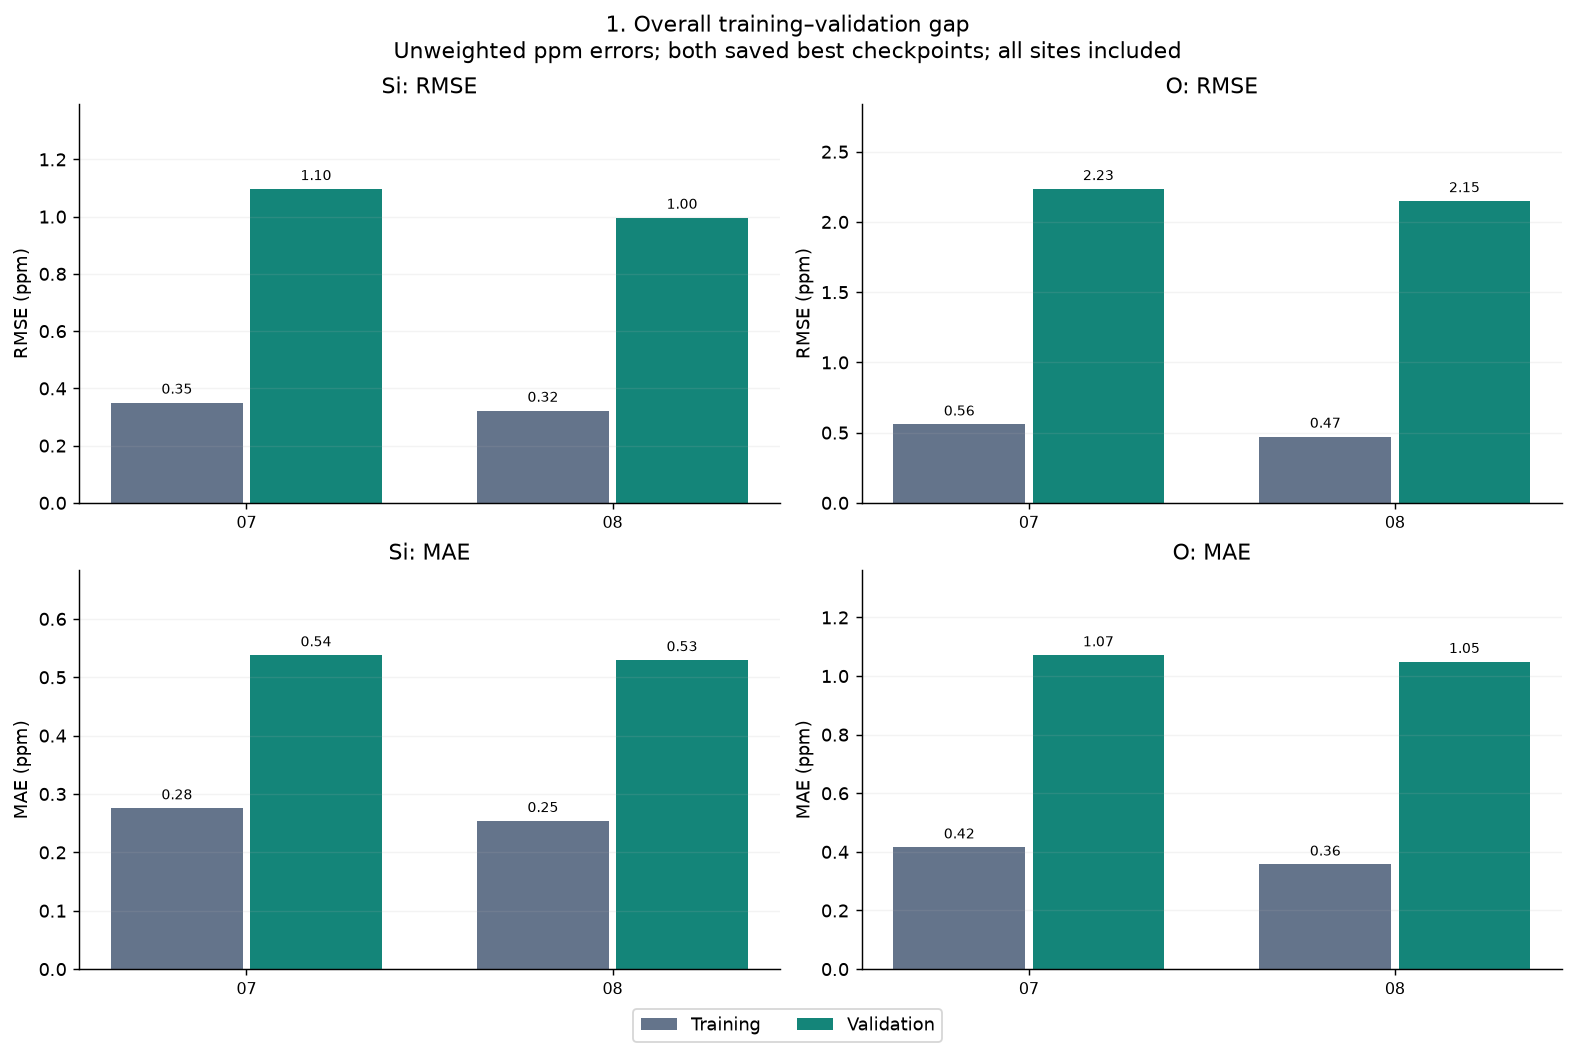

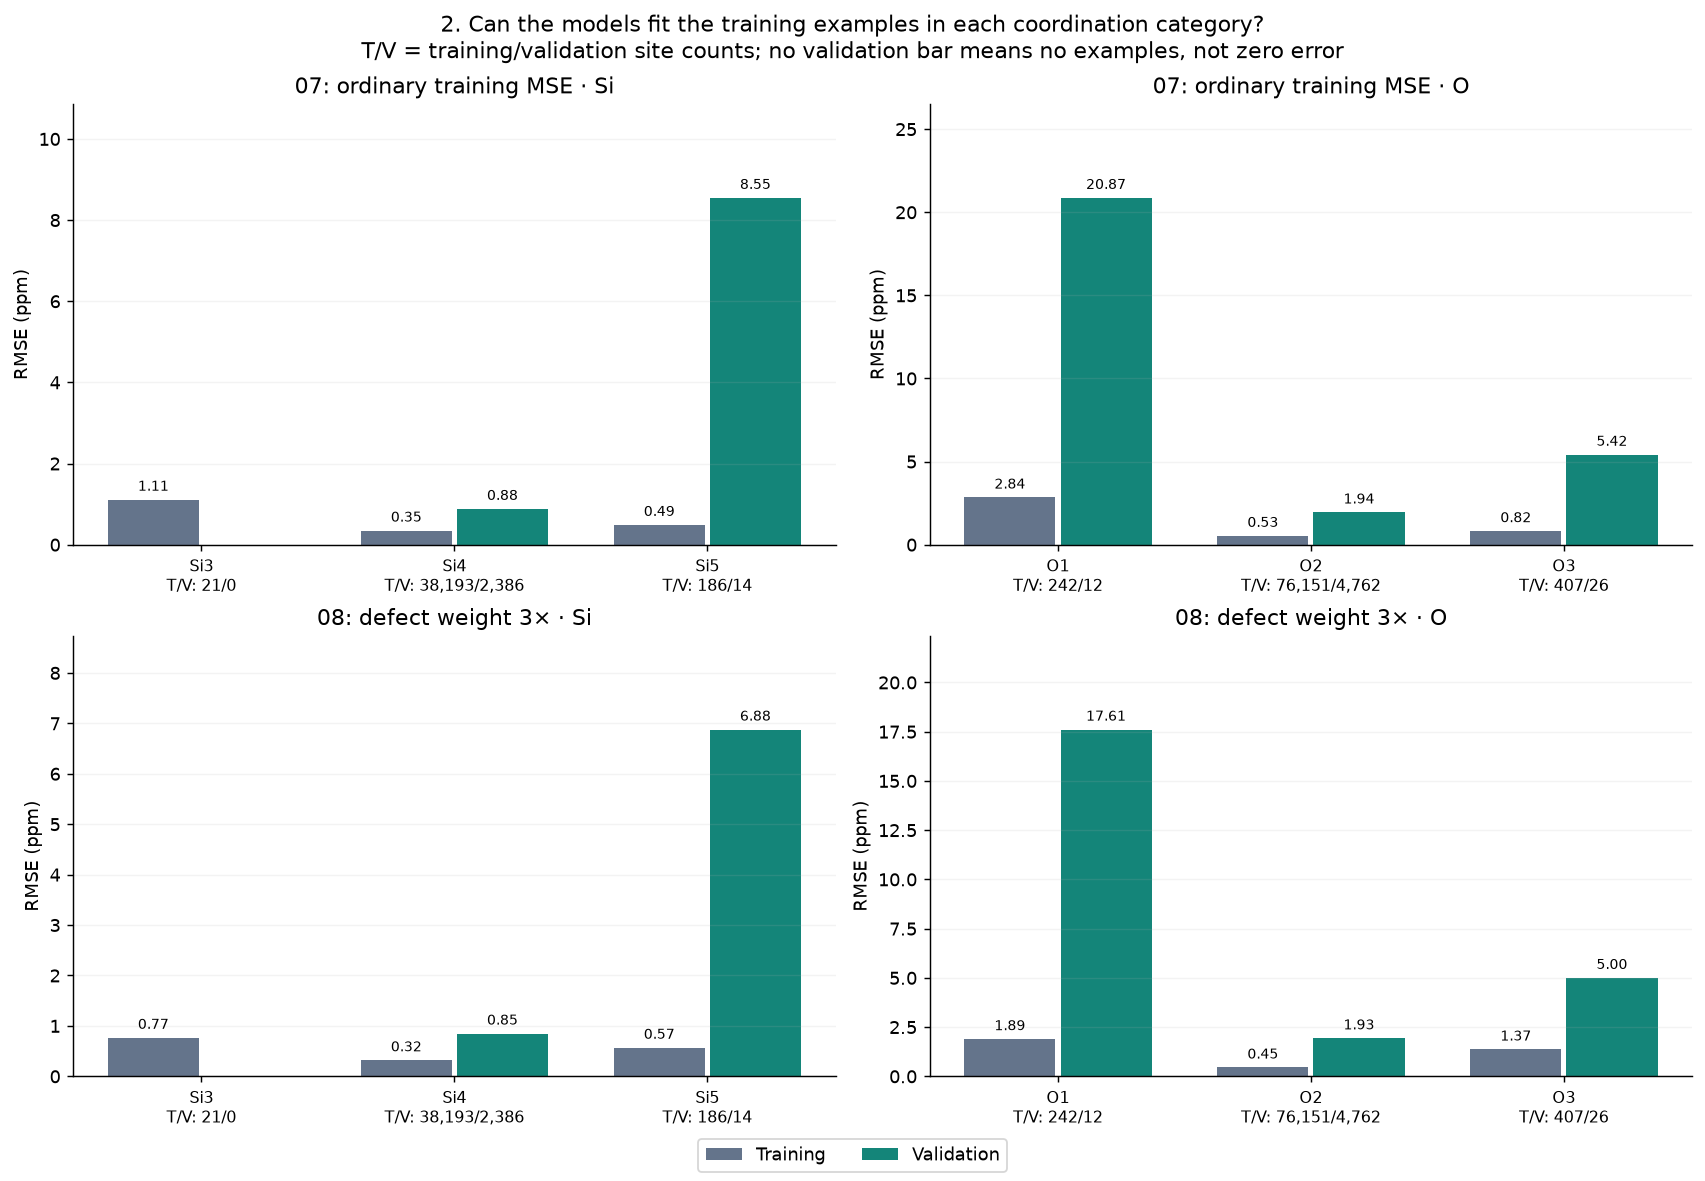

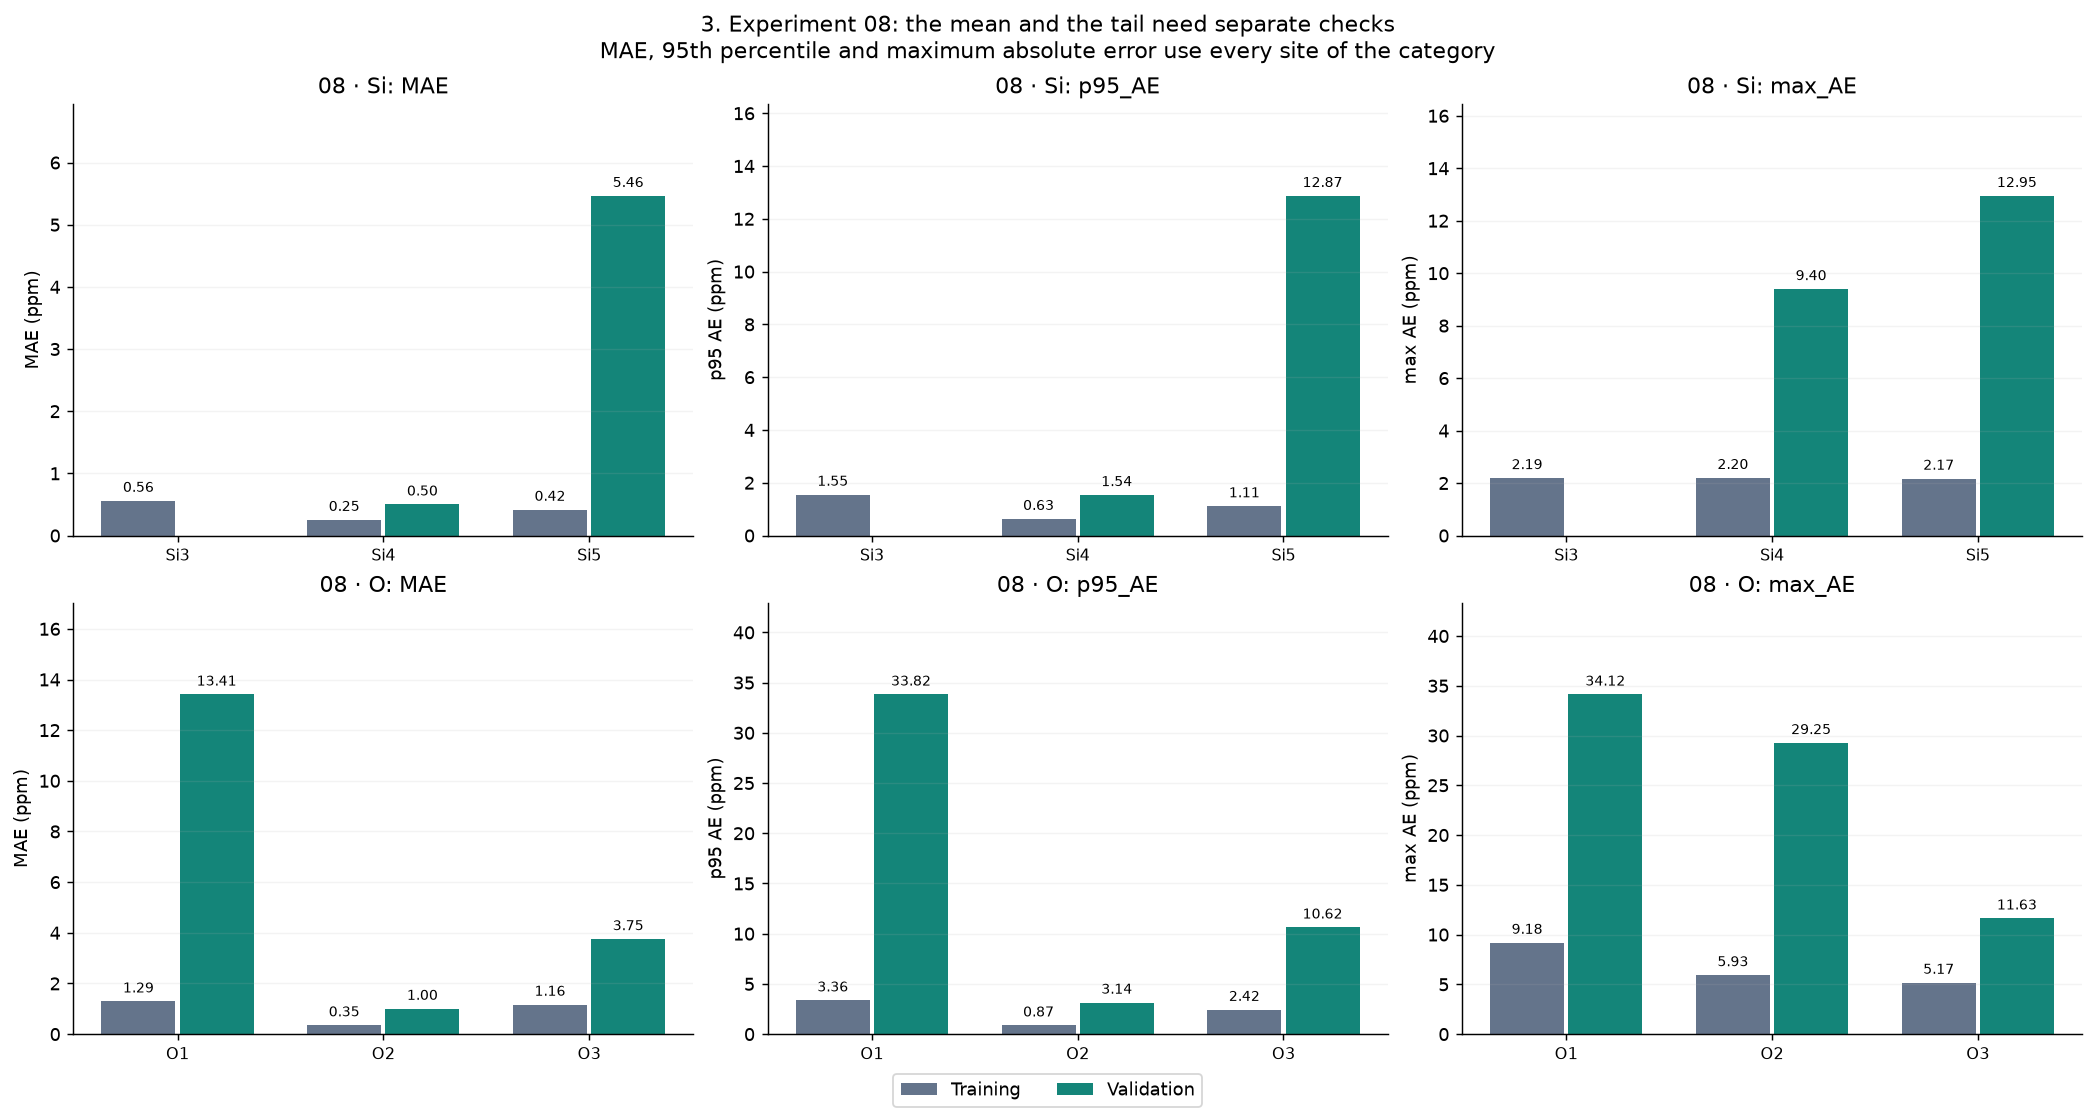

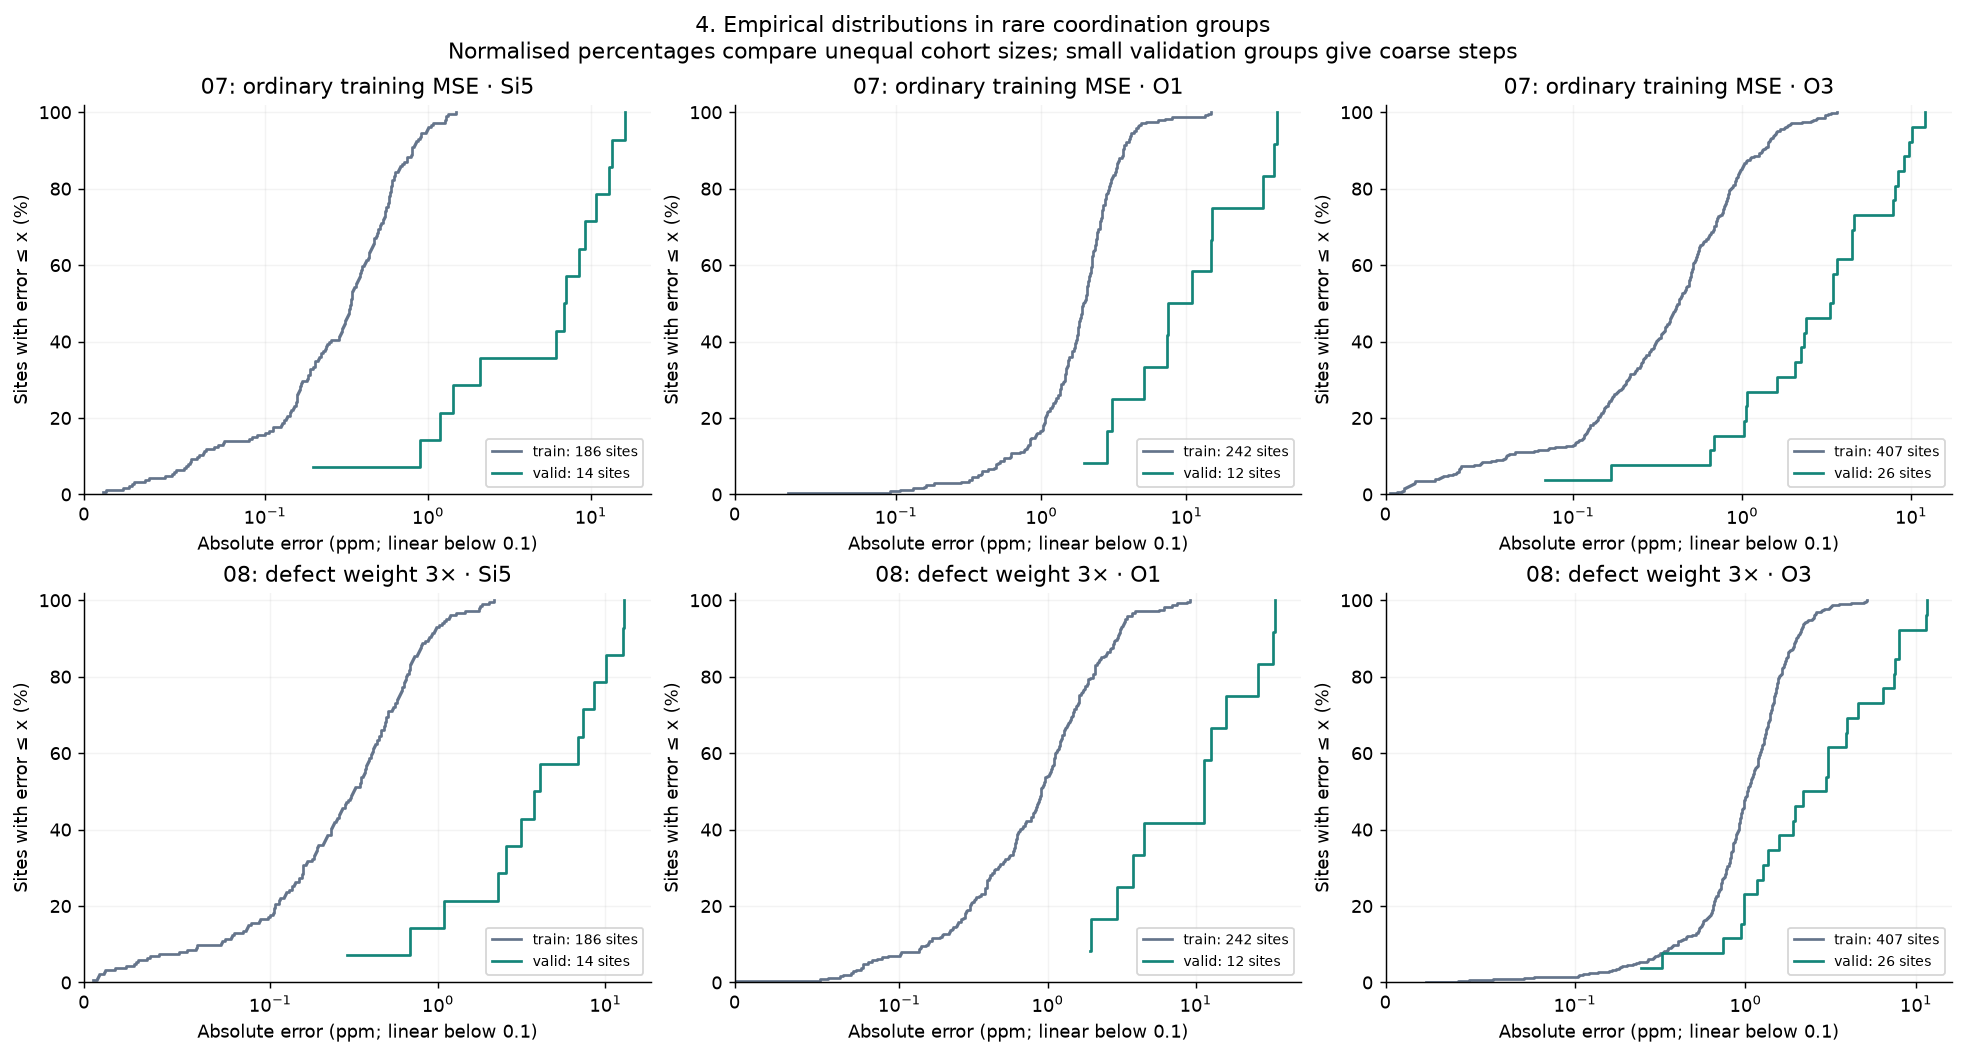

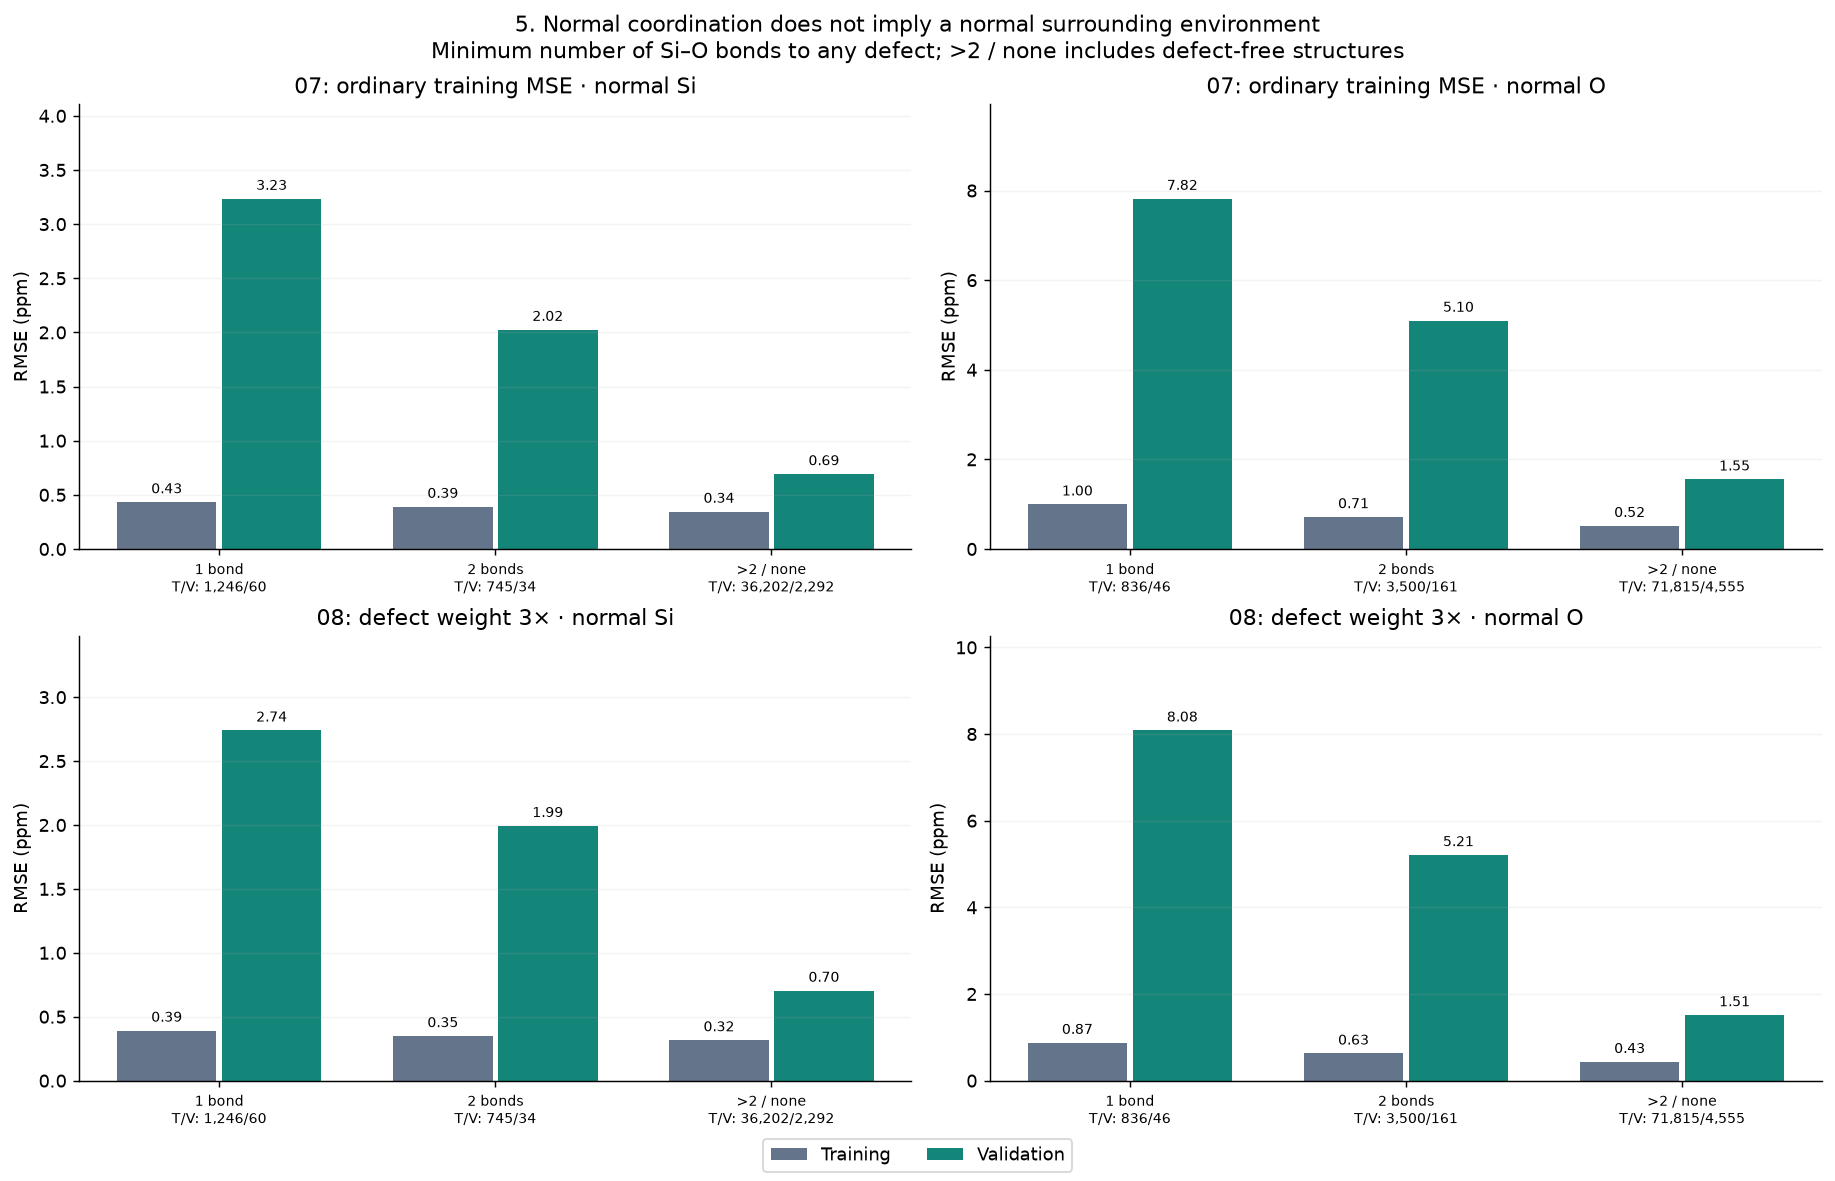

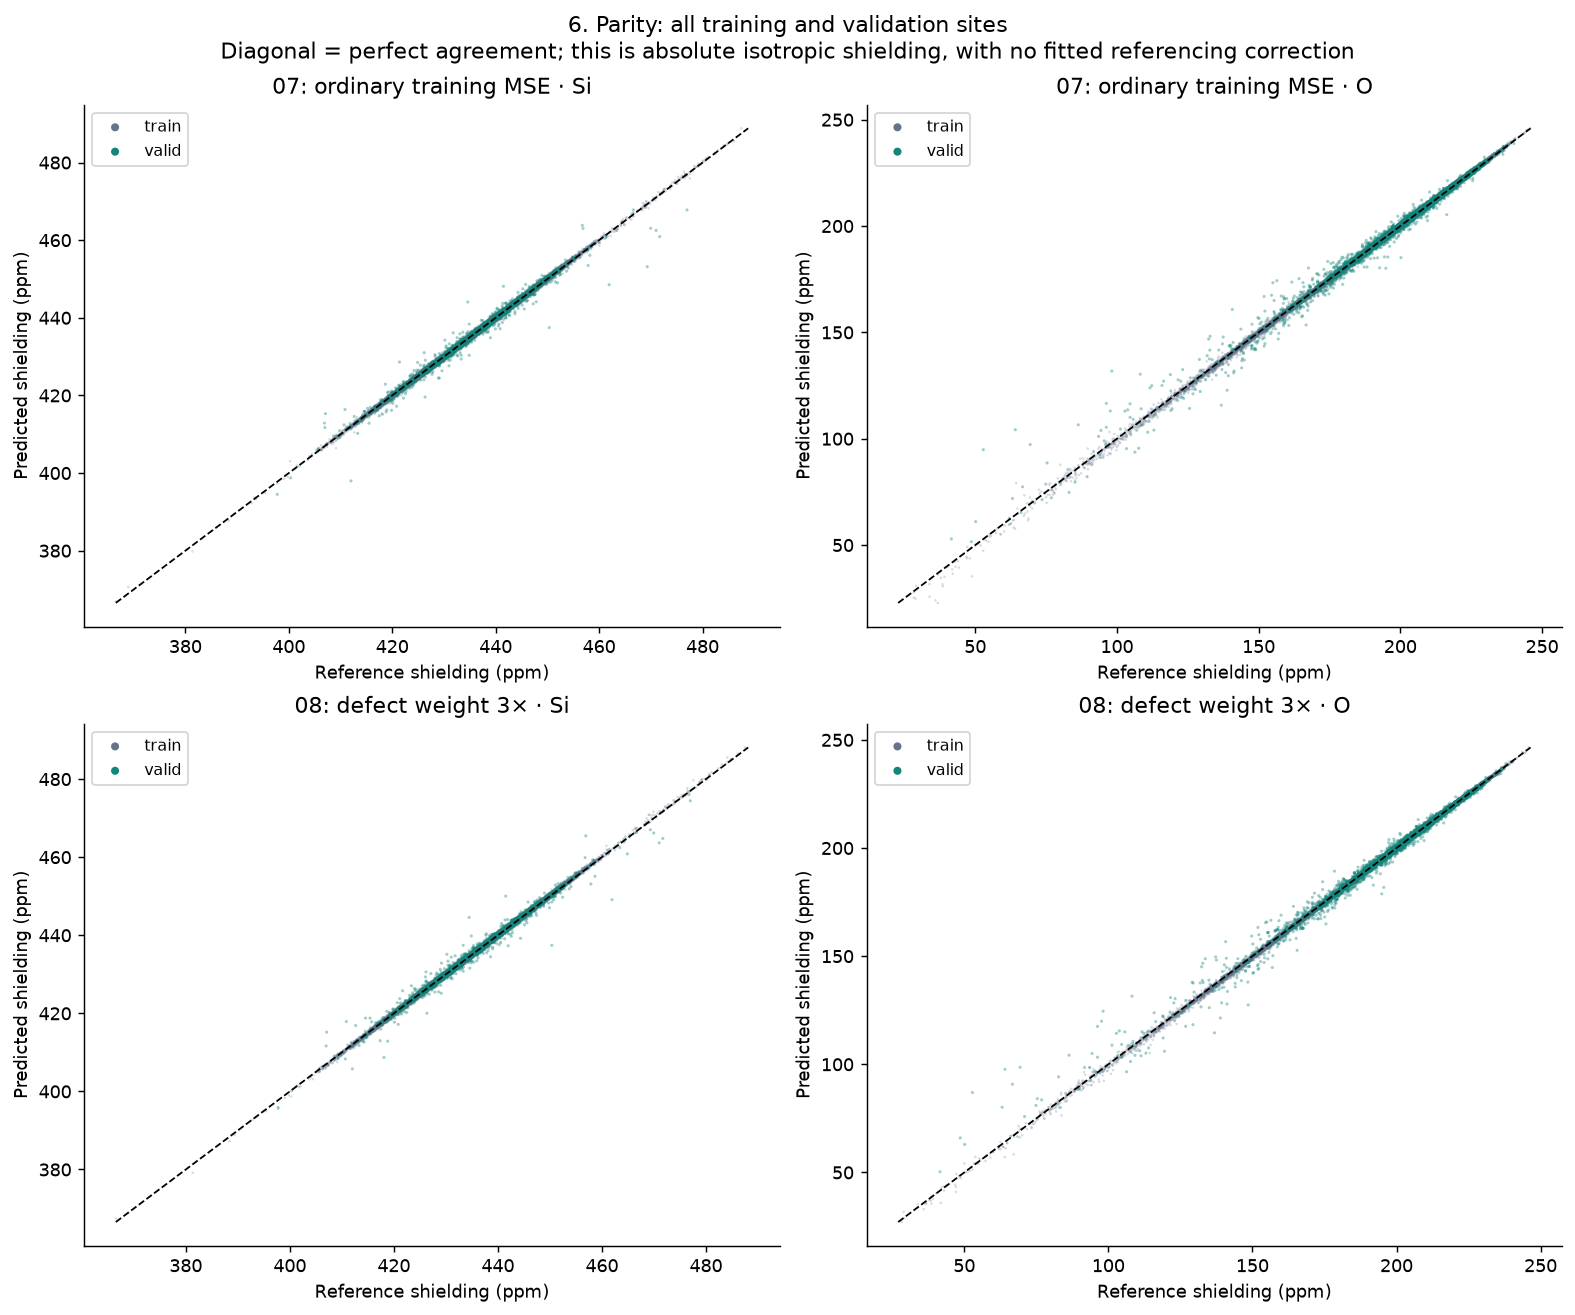

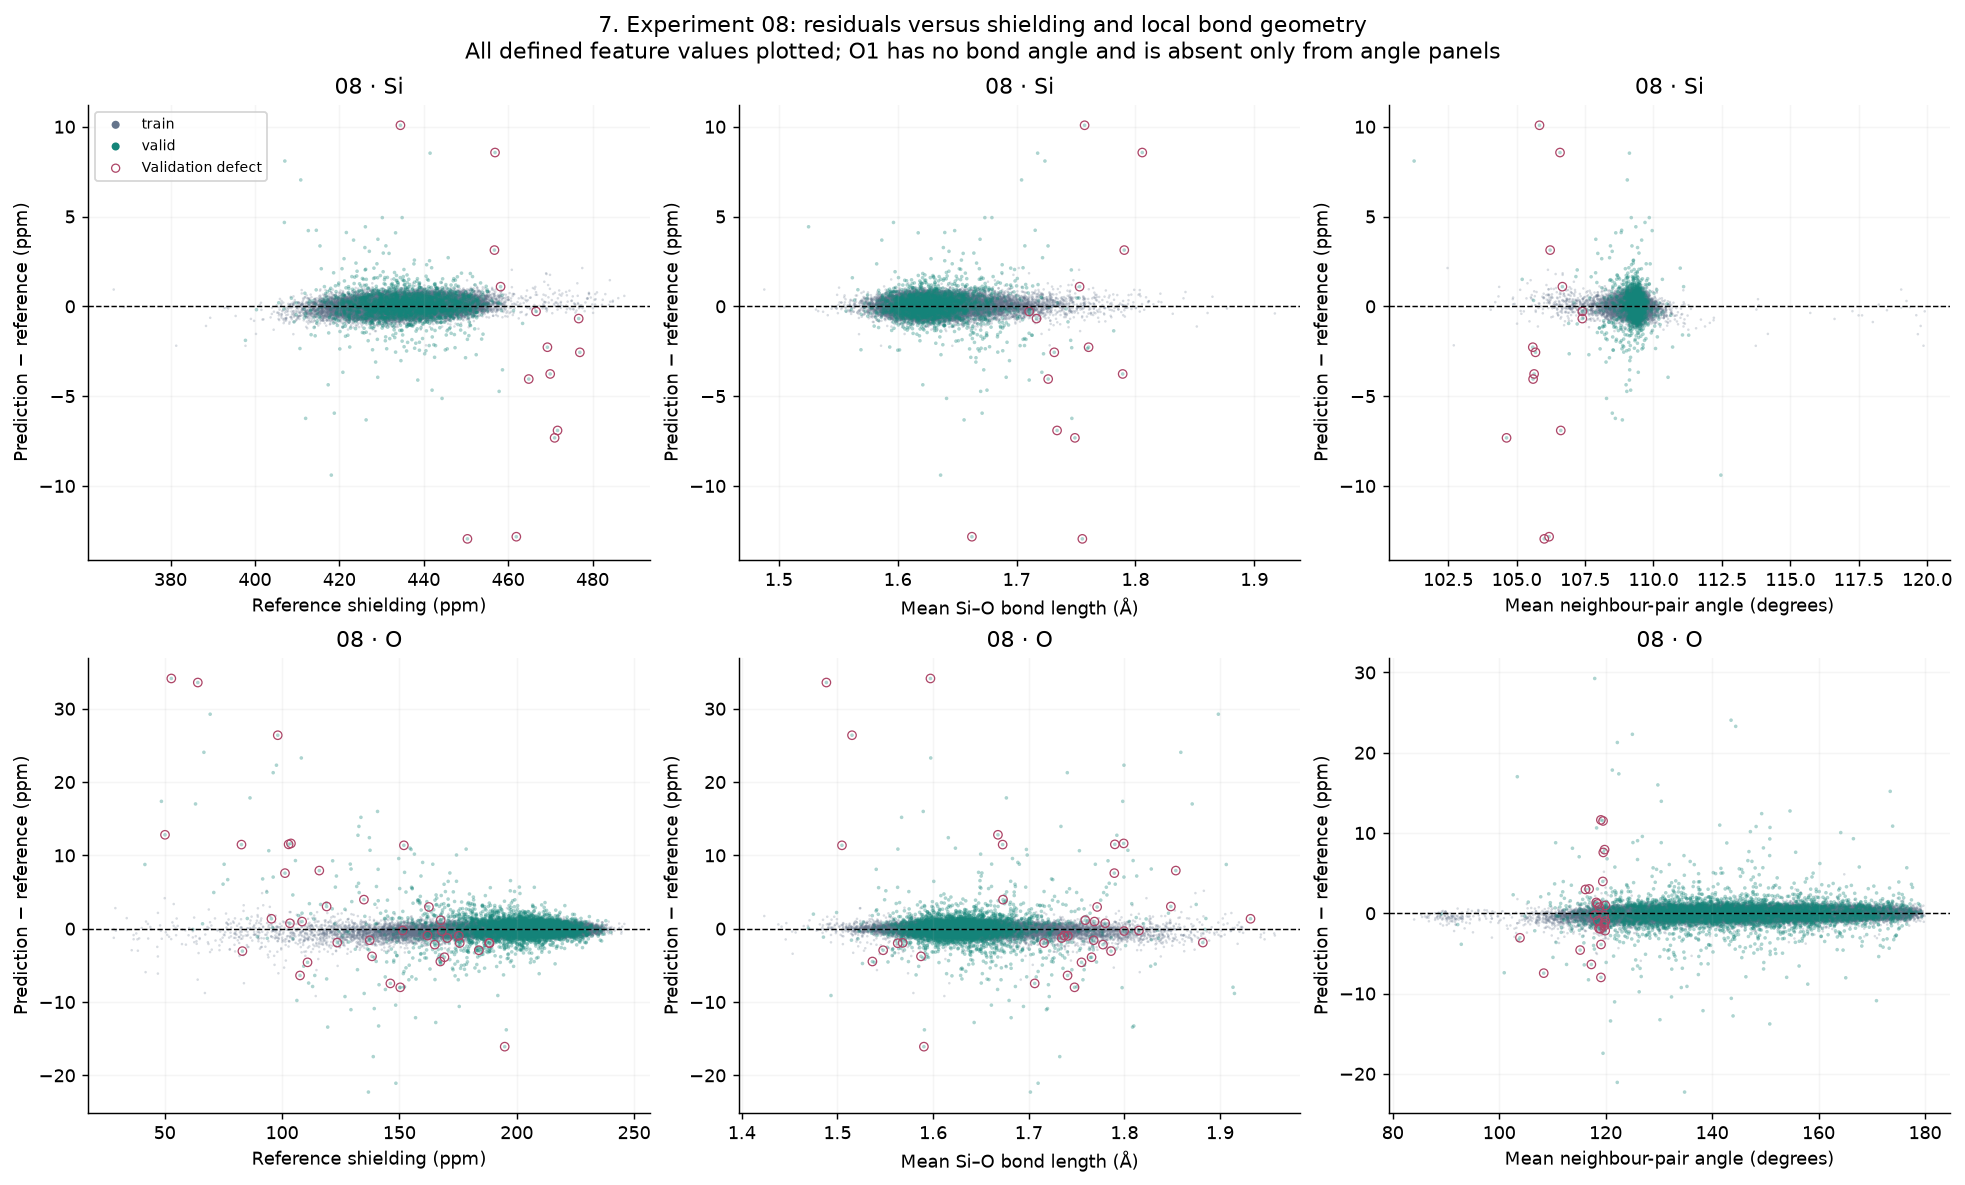

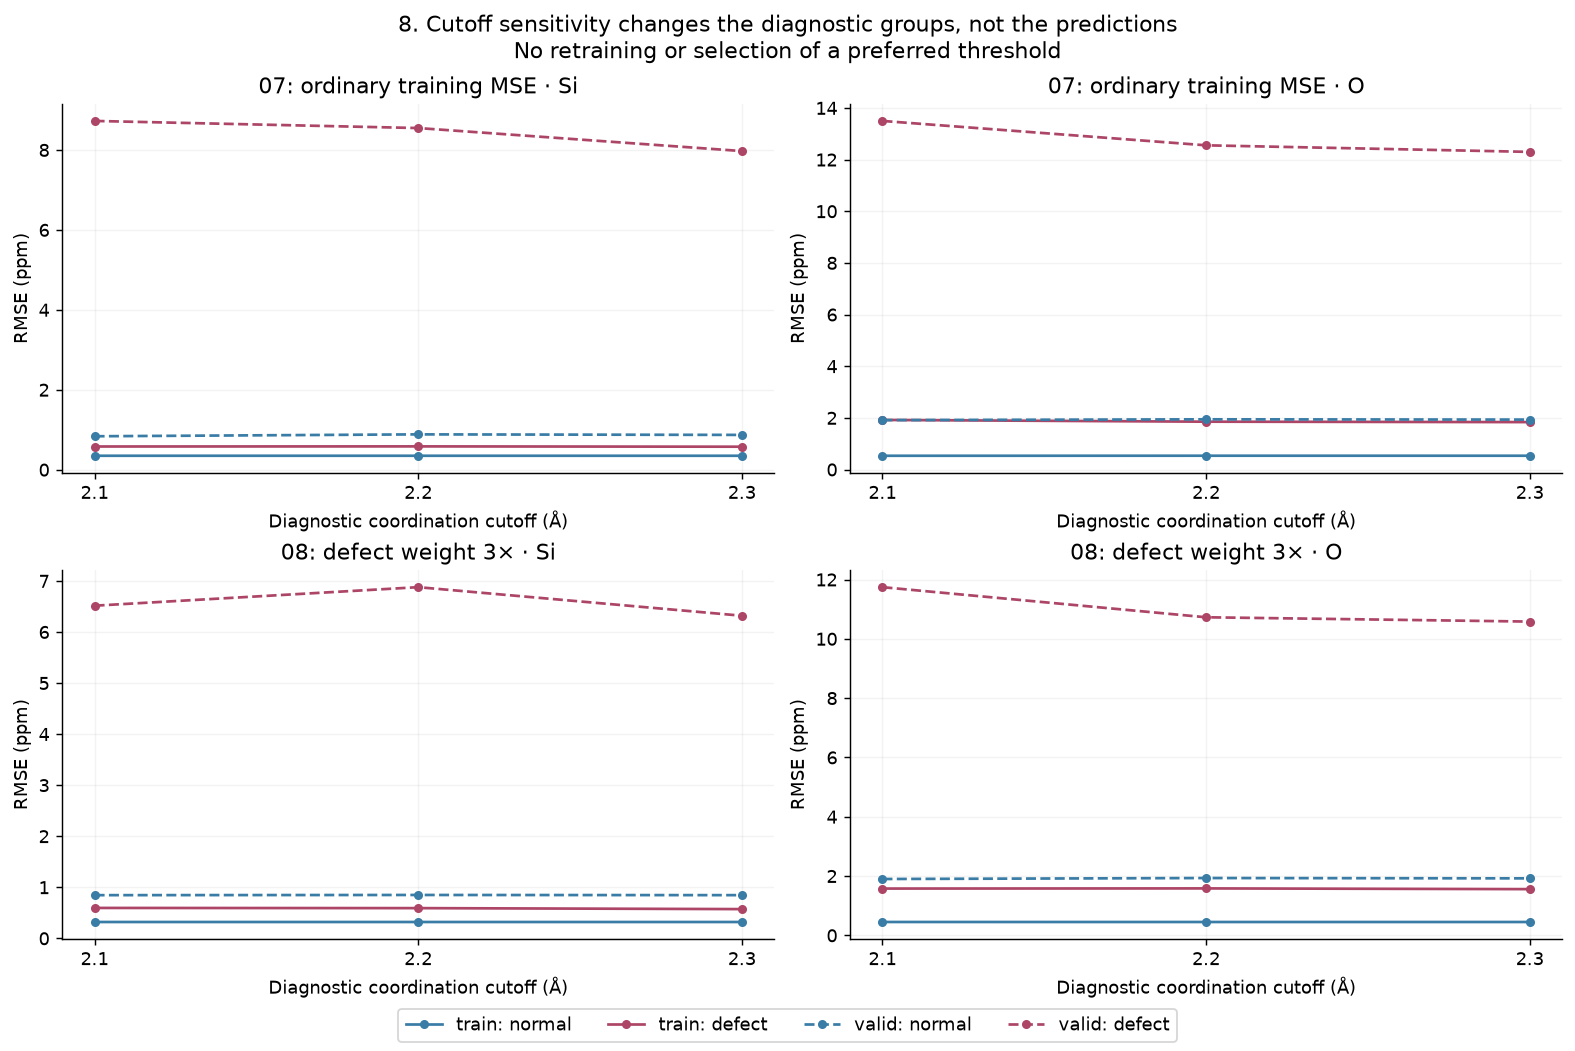

,cutoff_A,run,split,element,group,sites,structures,RMSE_ppm,MAE_ppm
0,2.1,07,train,O,Normal,76157,800,0.5326,0.4086
1,2.1,07,train,O,Defect,643,304,1.9195,1.2409
2,2.1,07,train,Si,Normal,38203,800,0.3489,0.2749
3,2.1,07,train,Si,Defect,197,153,0.5804,0.4290
4,2.1,07,valid,O,Normal,4764,50,1.9121,1.0172
5,2.1,07,valid,O,Defect,36,13,13.4972,8.2144
6,2.1,07,valid,Si,Normal,2384,50,0.8366,0.4942
7,2.1,07,valid,Si,Defect,16,6,8.7267,7.0446
8,2.1,08,train,O,Normal,76157,800,0.4510,0.3498
9,2.1,08,train,O,Defect,643,304,1.5779,1.2123


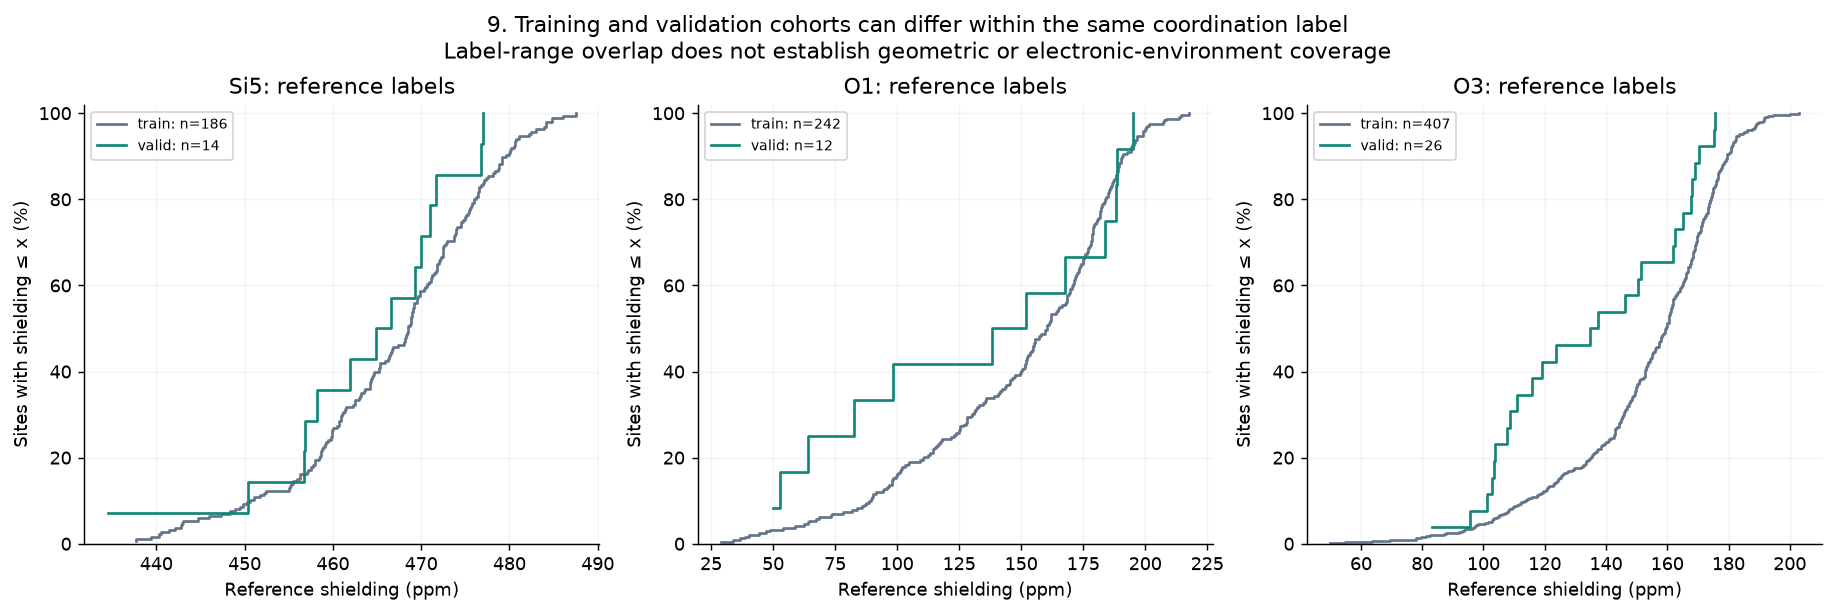

,category,train_min_ppm,train_max_ppm,valid_min_ppm,valid_max_ppm,valid_outside_group_train_range
0,Si5,437.6692,487.5304,434.4809,476.9944,1
1,O1,28.9838,217.7485,50.1367,194.8899,0
2,O3,50.0251,202.9383,83.1183,175.7238,0


In [6]:
TRAIN_COLOR='#64748b';VALID_COLOR='#148579';DEFECT_COLOR='#ad4567'
RUN_LABELS={'07':'07: ordinary training MSE','08':'08: defect weight 3×'}

def train_valid_bars(ax,frame,group,order,metric,title,counts=False):
    x=np.arange(len(order));finite=[]
    for split,shift,color,label in [('train',-.19,TRAIN_COLOR,'Training'),('valid',.19,VALID_COLOR,'Validation')]:
        part=frame[frame.split.eq(split)].set_index(group).reindex(order)
        values=part[metric].to_numpy(dtype=float)
        bars=ax.bar(x+shift,values,.36,color=color,label=label)
        ax.bar_label(bars,labels=[f'{v:.2f}' if np.isfinite(v) else '' for v in values],padding=3,fontsize=8)
        finite.extend(values[np.isfinite(values)].tolist())
    labels=[]
    for item in order:
        label=str(item)
        if counts:
            ns=[]
            for split in ['train','valid']:
                selected=frame[frame.split.eq(split)&frame[group].eq(item)]
                ns.append(int(selected.sites.iloc[0]) if len(selected) else 0)
            label+=f'\nT/V: {ns[0]:,}/{ns[1]:,}'
        labels.append(label)
    ax.set_xticks(x,labels,fontsize=9)
    ax.set_title(title);ax.set_ylabel(metric.replace('_ppm','').replace('_',' ')+' (ppm)')
    ax.set_ylim(0,max(finite+[.01])*1.27);ax.grid(axis='y',alpha=.15)

fig,axes=plt.subplots(2,2,figsize=(12,8),layout='constrained')
for col,el in enumerate(ELEMENTS):
    for row,metric in enumerate(['RMSE_ppm','MAE_ppm']):
        train_valid_bars(axes[row,col],metrics[metrics.element.eq(el)],'run',['07','08'],metric,f'{el}: {metric.split("_")[0]}')
fig.legend(*axes[0,0].get_legend_handles_labels(),loc='outside lower center',ncol=2)
fig.suptitle('1. Overall training–validation gap\nUnweighted ppm errors; both saved best checkpoints; all sites included')
plt.show()

fig,axes=plt.subplots(2,2,figsize=(13,9),layout='constrained')
for row,run_id in enumerate(RUNS):
    for col,el in enumerate(ELEMENTS):
        part=coordination_metrics[coordination_metrics.run.eq(run_id)&coordination_metrics.element.eq(el)]
        order=category_map.loc[category_map.element.eq(el),'category'].to_list()
        train_valid_bars(axes[row,col],part,'category',order,'RMSE_ppm',f'{RUN_LABELS[run_id]} · {el}',counts=True)
fig.legend(*axes[0,0].get_legend_handles_labels(),loc='outside lower center',ncol=2)
fig.suptitle('2. Can the models fit the training examples in each coordination category?\nT/V = training/validation site counts; no validation bar means no examples, not zero error')
plt.show()

fig,axes=plt.subplots(2,3,figsize=(16,8.5),layout='constrained')
for row,el in enumerate(ELEMENTS):
    part=coordination_metrics[coordination_metrics.run.eq('08')&coordination_metrics.element.eq(el)]
    order=category_map.loc[category_map.element.eq(el),'category'].to_list()
    for col,metric in enumerate(['MAE_ppm','p95_AE_ppm','max_AE_ppm']):
        train_valid_bars(axes[row,col],part,'category',order,metric,f'08 · {el}: {metric.replace("_ppm","")}')
fig.legend(*axes[0,0].get_legend_handles_labels(),loc='outside lower center',ncol=2)
fig.suptitle('3. Experiment 08: the mean and the tail need separate checks\nMAE, 95th percentile and maximum absolute error use every site of the category')
plt.show()

fig,axes=plt.subplots(2,3,figsize=(15,8),layout='constrained')
for row,run_id in enumerate(RUNS):
    for col,category in enumerate(['Si5','O1','O3']):
        ax=axes[row,col]
        for split,color in [('train',TRAIN_COLOR),('valid',VALID_COLOR)]:
            g=sites[sites.run.eq(run_id)&sites.split.eq(split)&sites.category.eq(category)]
            if len(g):
                e=np.sort(g.absolute_error_ppm.to_numpy())
                ax.step(e,100*np.arange(1,len(e)+1)/len(e),where='post',color=color,lw=1.5,label=f'{split}: {len(g)} sites')
        ax.set_xscale('symlog',linthresh=.1)
        ax.set_xlim(left=0)
        ax.set(title=f'{RUN_LABELS[run_id]} · {category}',xlabel='Absolute error (ppm; linear below 0.1)',ylabel='Sites with error ≤ x (%)',ylim=(0,102))
        ax.grid(alpha=.15);ax.legend(fontsize=8,loc='lower right')
fig.suptitle('4. Empirical distributions in rare coordination groups\nNormalised percentages compare unequal cohort sizes; small validation groups give coarse steps')
plt.show()

fig,axes=plt.subplots(2,2,figsize=(14,9),layout='constrained')
for row,run_id in enumerate(RUNS):
    for col,el in enumerate(ELEMENTS):
        part=proximity_metrics[proximity_metrics.run.eq(run_id)&proximity_metrics.element.eq(el)]
        train_valid_bars(axes[row,col],part,'proximity',PROXIMITY_ORDER[1:],'RMSE_ppm',f'{RUN_LABELS[run_id]} · normal {el}',counts=True)
        labels=[t.get_text().replace('Normal: ','').replace(' / unreachable',' / none') for t in axes[row,col].get_xticklabels()]
        axes[row,col].set_xticklabels(labels,fontsize=8)
fig.legend(*axes[0,0].get_legend_handles_labels(),loc='outside lower center',ncol=2)
fig.suptitle('5. Normal coordination does not imply a normal surrounding environment\nMinimum number of Si–O bonds to any defect; >2 / none includes defect-free structures')
plt.show()

fig,axes=plt.subplots(2,2,figsize=(12,10),layout='constrained')
for row,run_id in enumerate(RUNS):
    for col,el in enumerate(ELEMENTS):
        ax=axes[row,col];part=sites[sites.run.eq(run_id)&sites.element.eq(el)]
        for split,color,size,alpha in [('train',TRAIN_COLOR,2,.25),('valid',VALID_COLOR,3,.4)]:
            g=part[part.split.eq(split)]
            ax.scatter(g.reference_ppm,g.prediction_ppm,s=size,c=color,alpha=alpha,edgecolors='none',rasterized=True,label=split)
        lo=min(part.reference_ppm.min(),part.prediction_ppm.min());hi=max(part.reference_ppm.max(),part.prediction_ppm.max())
        ax.plot([lo,hi],[lo,hi],'--',color='black',lw=1)
        ax.set(title=f'{RUN_LABELS[run_id]} · {el}',xlabel='Reference shielding (ppm)',ylabel='Predicted shielding (ppm)')
        legend=ax.legend(loc='upper left',fontsize=9)
        for handle in legend.legend_handles:
            handle.set_alpha(1);handle.set_sizes([20])
fig.suptitle('6. Parity: all training and validation sites\nDiagonal = perfect agreement; this is absolute isotropic shielding, with no fitted referencing correction')
plt.show()

fig,axes=plt.subplots(2,3,figsize=(15,9),layout='constrained')
features=[('reference_ppm','Reference shielding (ppm)'),('mean_bond_A','Mean Si–O bond length (Å)'),('mean_angle_deg','Mean neighbour-pair angle (degrees)')]
for row,el in enumerate(ELEMENTS):
    part=sites[sites.run.eq('08')&sites.element.eq(el)]
    for col,(feature,label) in enumerate(features):
        ax=axes[row,col]
        for split,color,size,alpha in [('train',TRAIN_COLOR,2,.25),('valid',VALID_COLOR,4,.35)]:
            g=part[part.split.eq(split)&part[feature].notna()]
            ax.scatter(g[feature],g.error_ppm,s=size,c=color,alpha=alpha,edgecolors='none',rasterized=True,label=split)
        defects=part[part.split.eq('valid')&part.defect&part[feature].notna()]
        ax.scatter(defects[feature],defects.error_ppm,s=22,facecolors='none',edgecolors=DEFECT_COLOR,lw=.7,label='Validation defect')
        ax.axhline(0,color='black',ls='--',lw=.8)
        ax.set(title=f'08 · {el}',xlabel=label,ylabel='Prediction − reference (ppm)');ax.grid(alpha=.12)
        if row==0 and col==0:
            legend=ax.legend(fontsize=8)
            for handle in legend.legend_handles:
                handle.set_alpha(1);handle.set_sizes([20])
fig.suptitle('7. Experiment 08: residuals versus shielding and local bond geometry\nAll defined feature values plotted; O1 has no bond angle and is absent only from angle panels')
plt.show()

fig,axes=plt.subplots(2,2,figsize=(12,8),layout='constrained')
for row,run_id in enumerate(RUNS):
    for col,el in enumerate(ELEMENTS):
        ax=axes[row,col]
        for split,style in [('train','-'),('valid','--')]:
            for group,color in [('Normal','#397ca6'),('Defect',DEFECT_COLOR)]:
                g=sensitivity_metrics[sensitivity_metrics.run.eq(run_id)&sensitivity_metrics.split.eq(split)&sensitivity_metrics.element.eq(el)&sensitivity_metrics.group.eq(group)].sort_values('cutoff_A')
                ax.plot(g.cutoff_A,g.RMSE_ppm,style+'o',color=color,ms=4,label=f'{split}: {group.lower()}')
        ax.set(title=f'{RUN_LABELS[run_id]} · {el}',xlabel='Diagnostic coordination cutoff (Å)',ylabel='RMSE (ppm)',xticks=[2.1,2.2,2.3])
        ax.grid(alpha=.15)
fig.legend(*axes[0,0].get_legend_handles_labels(),loc='outside lower center',ncol=4)
fig.suptitle('8. Cutoff sensitivity changes the diagnostic groups, not the predictions\nNo retraining or selection of a preferred threshold')
plt.show()
display(sensitivity_metrics[['cutoff_A','run','split','element','group','sites','structures','RMSE_ppm','MAE_ppm']].round(4))

fig,axes=plt.subplots(1,3,figsize=(14,4.6),layout='constrained')
coverage_rows=[]
for ax,category in zip(axes,['Si5','O1','O3']):
    # Labels are identical for both models; include each site once.
    part=sites[sites.run.eq('08')&sites.category.eq(category)]
    train=part[part.split.eq('train')].reference_ppm
    valid=part[part.split.eq('valid')].reference_ppm
    for split,color in [('train',TRAIN_COLOR),('valid',VALID_COLOR)]:
        values=np.sort(part.loc[part.split.eq(split),'reference_ppm'].to_numpy())
        if len(values):ax.step(values,100*np.arange(1,len(values)+1)/len(values),where='post',color=color,label=f'{split}: n={len(values)}')
    outside=int(((valid<train.min())|(valid>train.max())).sum())
    coverage_rows.append({'category':category,'train_min_ppm':train.min(),'train_max_ppm':train.max(),
                         'valid_min_ppm':valid.min(),'valid_max_ppm':valid.max(),'valid_outside_group_train_range':outside})
    ax.set(title=f'{category}: reference labels',xlabel='Reference shielding (ppm)',ylabel='Sites with shielding ≤ x (%)',ylim=(0,102))
    ax.legend(fontsize=8);ax.grid(alpha=.15)
fig.suptitle('9. Training and validation cohorts can differ within the same coordination label\nLabel-range overlap does not establish geometric or electronic-environment coverage')
plt.show()
category_coverage=pd.DataFrame(coverage_rows)
display(category_coverage.round(4))


## 6. Conclusions and reproducibility

Use absolute ppm errors, the tail metrics and the number of supporting structures together. A small training error with a much larger validation error supports a generalisation/coverage concern; it does not prove the exact cause or guarantee that collecting arbitrary extra data will help. High errors on both splits would motivate a controlled small-training-subset fitting probe. Strong training performance on its own does not establish physical correctness or accuracy outside the training domain.

The current checkpoints were selected using validation loss. Evaluating their training residuals is legitimate for this diagnostic, but it remains a development analysis. No validation examples should be added to training based on these figures.


In [7]:
lines=['### Measured training–validation gaps',
       'Both models were evaluated freshly on 800 training structures and 50 validation structures. All errors below are unweighted.',
       '', '| Model | Category | Training sites / structures | Validation sites / structures | Train RMSE (ppm) | Valid RMSE (ppm) | Gap (ppm) | Valid / train |',
       '|---|---|---:|---:|---:|---:|---:|---:|']
for r in gap.itertuples():
    lines.append(f'| {r.run} | {r.category} | {int(r.sites_train)} / {int(r.structures_train)} | {int(r.sites_valid)} / {int(r.structures_valid)} | {r.RMSE_ppm_train:.3f} | {r.RMSE_ppm_valid:.3f} | {r.RMSE_gap_ppm:.3f} | {r.RMSE_ratio_valid_train:.1f} |')
lines+=['','Missing categories have undefined errors (`nan`), not zero error.']
for category in ['Si5','O1','O3']:
    r=gap[gap.run.eq('08')&gap.category.eq(category)].iloc[0]
    lines.append(f'- **08 {category}:** training RMSE {r.RMSE_ppm_train:.3f} versus validation {r.RMSE_ppm_valid:.3f} ppm; training maximum absolute error {r.max_AE_ppm_train:.3f} versus validation {r.max_AE_ppm_valid:.3f} ppm.')
rare=gap[gap.run.eq('08')&gap.category.isin(['Si5','O1','O3'])]
if (rare.RMSE_ratio_valid_train>3).all():
    lines+=['','**Observed pattern:** validation RMSE is more than three times training RMSE in all three focal defect categories. The model fits the supplied training examples substantially better than the validation examples. This favours investigating generalisation, structural coverage and distribution differences before claiming that the architecture cannot fit these coordination types. The factor of three is a descriptive contrast, not a statistical test or a universal decision threshold.']
else:
    lines+=['','**Observed pattern:** the gap varies by defect category. Use the group-specific absolute errors and tails to decide whether a fitting probe or coverage analysis should come first; do not assume a single limitation for all coordination types.']
lines+=['','**Next decision:** if training defects are already fitted well, prioritise training-side coverage analysis and the controlled coverage learning curve described in experiment 08. If important training outliers remain, inspect those and run the small-training-subset fitting probe before increasing loss weights. Error versus defect proximity tests whether direct coordination misses neighbouring hard sites; it does not by itself establish causality.',
         '', '**Limits:** training and validation groups contain different structures and shielding distributions; the small validation defect cohorts and checkpoint selection limit generality. Low training error does not prove sufficient physics or future extrapolation. Si3 cannot be assessed for generalisation if absent from validation.']
display(Markdown('\n'.join(lines)))
manifest={'evaluation_utc':datetime.now(timezone.utc).isoformat(),'models':provenance.reset_index().to_dict('records'),
    'data_sha256':data_hashes,'counts':audit.reset_index().to_dict('records'),
    'versions':versions,'python':platform.python_version(),'target':'absolute isotropic shielding trace(ms)/3, ppm',
    'predictions':'fresh for all 800 train and 50 validation structures, for both models',
    'loss_for_metrics':'unweighted per-site residual statistics; no 1000 multiplier',
    'model_mode':'eval, no_grad, state checked unchanged; no refit',
    'cutoff_A':6.0,'coordination_cutoff_A':2.2,'sensitivity_cutoffs_A':[2.1,2.2,2.3],
    'normal_proximity':'minimum graph hops to any direct defect, disjoint 1,2,>2/unreachable',
    'test_data_loaded':False,'error_sign':'prediction minus reference',
    'helper_sha256':sha256(PROJECT/'nmr_helpers/extract_ms_isotropy.py'),'torch_threads':THREADS}
print(json.dumps(manifest,indent=2))


{
  "evaluation_utc": "2026-10-14T15:05:33.014066+00:00",
  "models": [
    {
      "run": "07",
      "run_name": "TensorNequIP-NMR-9065266",
      "best_epoch": 188,
      "model_sha256": "f2159b2fe9bd80147c46b55413c233cd616d825c976e75bf80de345f4104b32a",
      "config_sha256": "7e510894939e38f50da45b5fb23dadcf0932b70a627f3661bda73e15d798a209",
      "best_checkpoint_sha256": "4d93d7073e527b408e9450efbb289901e87670b2bfd9d2b183cdcb1bf31e490c",
      "saved_valid_MSE": 3.731101318359375
    },
    {
      "run": "08",
      "run_name": "TensorNequIP-NMR-Coord3x-9083627",
      "best_epoch": 287,
      "model_sha256": "e6b96cb04593adc1761b682a0d070a34c49c3de329493ef39016074ca6b625e6",
      "config_sha256": "937013dd35accfa52183d1399e78b7c924bdd80094569b3d336f61ce46088063",
      "best_checkpoint_sha256": "64f652c9275f83519bfb5f92eaf771e82d44920cac39fb1c88324a4f242b4199",
      "saved_valid_MSE": 3.409656494140625
    }
  ],
  "data_sha256": {
    "train": "77de1ed9983781e906c35aa63d4f1

### Measured training–validation gaps
Both models were evaluated freshly on 800 training structures and 50 validation structures. All errors below are unweighted.

| Model | Category | Training sites / structures | Validation sites / structures | Train RMSE (ppm) | Valid RMSE (ppm) | Gap (ppm) | Valid / train |
|---|---|---:|---:|---:|---:|---:|---:|
| 07 | O1 | 242 / 202 | 12 / 10 | 2.841 | 20.868 | 18.026 | 7.3 |
| 07 | O2 | 76151 / 800 | 4762 / 50 | 0.534 | 1.944 | 1.409 | 3.6 |
| 07 | O3 | 407 / 292 | 26 / 13 | 0.819 | 5.416 | 4.596 | 6.6 |
| 07 | Si3 | 21 / 19 | 0 / 0 | 1.112 | nan | nan | nan |
| 07 | Si4 | 38193 / 800 | 2386 / 50 | 0.349 | 0.884 | 0.535 | 2.5 |
| 07 | Si5 | 186 / 135 | 14 / 5 | 0.489 | 8.549 | 8.060 | 17.5 |
| 08 | O1 | 242 / 202 | 12 / 10 | 1.893 | 17.611 | 15.718 | 9.3 |
| 08 | O2 | 76151 / 800 | 4762 / 50 | 0.451 | 1.933 | 1.482 | 4.3 |
| 08 | O3 | 407 / 292 | 26 / 13 | 1.366 | 5.001 | 3.634 | 3.7 |
| 08 | Si3 | 21 / 19 | 0 / 0 | 0.766 | nan | nan | nan |
| 08 | Si4 | 38193 / 800 | 2386 / 50 | 0.320 | 0.849 | 0.529 | 2.7 |
| 08 | Si5 | 186 / 135 | 14 / 5 | 0.569 | 6.878 | 6.309 | 12.1 |

Missing categories have undefined errors (`nan`), not zero error.
- **08 Si5:** training RMSE 0.569 versus validation 6.878 ppm; training maximum absolute error 2.171 versus validation 12.946 ppm.
- **08 O1:** training RMSE 1.893 versus validation 17.611 ppm; training maximum absolute error 9.184 versus validation 34.124 ppm.
- **08 O3:** training RMSE 1.366 versus validation 5.001 ppm; training maximum absolute error 5.167 versus validation 11.630 ppm.

**Observed pattern:** validation RMSE is more than three times training RMSE in all three focal defect categories. The model fits the supplied training examples substantially better than the validation examples. This favours investigating generalisation, structural coverage and distribution differences before claiming that the architecture cannot fit these coordination types. The factor of three is a descriptive contrast, not a statistical test or a universal decision threshold.

**Next decision:** if training defects are already fitted well, prioritise training-side coverage analysis and the controlled coverage learning curve described in experiment 08. If important training outliers remain, inspect those and run the small-training-subset fitting probe before increasing loss weights. Error versus defect proximity tests whether direct coordination misses neighbouring hard sites; it does not by itself establish causality.

**Limits:** training and validation groups contain different structures and shielding distributions; the small validation defect cohorts and checkpoint selection limit generality. Low training error does not prove sufficient physics or future extrapolation. Si3 cannot be assessed for generalisation if absent from validation.

## 7. What this evaluation changes

**The strongest observed problem is a training–validation gap, particularly for five-coordinate Si and one-coordinate O.** Experiment 08 has training/validation RMSE of **0.569/6.878 ppm for Si5**, **1.893/17.611 ppm for O1**, and **1.366/5.001 ppm for O3** (Figures 2–4). Thus the model can fit many supplied training examples of these coordination types much more accurately than validation examples. This weakens a blanket claim that TensorNequIP cannot represent these environments. It does not establish whether the cause is limited structural diversity, distribution differences, regularisation or another generalisation limitation.

**Weighting did not simply improve the fit of every training defect category.** Between the selected experiment-07 and experiment-08 checkpoints:

| Category | Training RMSE 07 → 08 (ppm) | Validation RMSE 07 → 08 (ppm) |
|---|---:|---:|
| Si5 | 0.489 → 0.569 | 8.549 → 6.878 |
| O1 | 2.841 → 1.893 | 20.868 → 17.611 |
| O3 | 0.819 → 1.366 | 5.416 → 5.001 |

The improvement on validation Si5 and O3 occurs despite worse training RMSE in those categories. These are different validation-selected training endpoints (epochs 188 and 287), so this does not isolate a causal regularisation effect; it shows that “more weight means uniformly tighter fitting” is not an adequate account of these runs.

**The difficult region extends to normally coordinated neighbours.** In experiment 08, normal O one bond from a defect has validation RMSE **8.084 ppm**, two bonds away **5.208 ppm**, and farther than two bonds/no reachable defect **1.513 ppm**. Corresponding training values are **0.874, 0.627 and 0.433 ppm**. Normal Si one bond away has validation RMSE **2.740 ppm**, versus **0.704 ppm** farther away (Figure 5). This supports investigating defect neighbourhoods rather than only the central atom's coordination. It is an association, not proof that proximity itself causes the errors; a large outlier can also occur in the farther group.

**There is still a fitting issue worth inspecting within O1.** Its training maximum absolute error is **9.184 ppm**, compared with **34.124 ppm** on validation (Figure 3). Training fit is substantially better but not uniformly excellent. The worst-training-site table gives the structures/atoms to inspect before an optional small-subset fitting probe.

**Coverage needs to be checked within categories.** One of the 14 validation Si5 sites has a shielding below the training Si5 label range, even though it is inside the overall training Si label range. All validation O1/O3 labels lie within their respective training category ranges; this does not demonstrate coverage of their local geometries (Figure 9). Coordination diagnostics at 2.1, 2.2 and 2.3 Å retain a substantial train–validation gap (Figure 8), so the observation is not solely an artefact of choosing exactly 2.2 Å.

**Recommended next step:** prioritise a training-side structural coverage analysis and the controlled coverage experiment from notebook 08, while separately inspecting the largest training O1 residuals. Do not assume that increasing the loss multiplier again will remove the validation outliers. A targeted fitting probe remains useful for the stubborn training examples; it is less urgent as a blanket test of whether Si5 can be fitted at all.

Only 14 Si5, 12 O1 and 26 O3 validation sites support these category-specific estimates. They occupy five, ten and thirteen structures respectively. Si3 has no validation examples, so its generalisation cannot be assessed here. These results describe the selected checkpoints and supplied splits, not performance across training seeds or a final independent test.
